In [9]:
!pip install -q pypdf sentence-transformers faiss-cpu groq gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 395.5/395.5 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 63.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.8/143.8 kB 4.1 MB/s eta 0:00:00


In [11]:
import os
import numpy as np

from google.colab import files
from pypdf import PdfReader

from sentence_transformers import SentenceTransformer
import faiss

from getpass import getpass
from groq import Groq

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [12]:
# ============================================
# GROQ CONNECTION
# ============================================

groq_api_key = getpass("🔑 Enter your Groq API key: ")

client = Groq(
    api_key=groq_api_key.strip()
)

print("✅ Groq connected successfully!")

🔑 Enter your Groq API key: ··········
✅ Groq connected successfully!


In [13]:
response = client.chat.completions.create(
    model="openai/gpt-oss-120b",
    messages=[
        {
            "role": "user",
            "content": "Say hello to my AI Second Brain in one sentence."
        }
    ],
    temperature=0.2
)

print(response.choices[0].message.content)

Hello, Second Brain—ready to amplify your ideas, organize your thoughts, and turn curiosity into brilliance!


In [14]:
print("📚 Upload a PDF for your AI Second Brain")

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

print("\n✅ Document uploaded!")
print("📄 File:", file_name)

📚 Upload a PDF for your AI Second Brain


Saving Cyber_Security_Second_Brain_Test.pdf to Cyber_Security_Second_Brain_Test.pdf

✅ Document uploaded!
📄 File: Cyber_Security_Second_Brain_Test.pdf


In [15]:
reader = PdfReader(file_name)

all_text = ""

for page_number, page in enumerate(reader.pages, start=1):

    text = page.extract_text()

    if text:
        all_text += text + "\n"

print("✅ PDF reading completed!")
print("📄 File:", file_name)
print("📑 Pages:", len(reader.pages))
print("📝 Characters:", len(all_text))

print("\n--- PDF PREVIEW ---\n")
print(all_text[:3000])

✅ PDF reading completed!
📄 File: Cyber_Security_Second_Brain_Test.pdf
📑 Pages: 1
📝 Characters: 1765

--- PDF PREVIEW ---

Cyber Security Fundamentals
A Test Document for AI Second Brain
Cyber security is the practice of protecting computers, networks, applications, devices, and data from
unauthorized access, attacks, damage, or disruption.
1. Common Cyber Threats
Malware is malicious software designed to damage systems, steal information, or gain unauthorized access.
Examples include viruses, worms, trojans, ransomware, and spyware.
Phishing is a social engineering attack in which an attacker sends a fraudulent message to trick a person into
revealing passwords, financial information, or other sensitive data.
Denial-of-Service (DoS) attacks attempt to make a service or network unavailable by overwhelming it with
requests or traffic. A Distributed Denial-of-Service (DDoS) attack uses multiple systems to generate the
traffic.
2. Cyber Threat Intelligence
Cyber Threat Intelligence (CTI) i

In [16]:
def create_chunks(text, chunk_size=800, overlap=150):

    chunks = []

    start = 0

    while start < len(text):

        end = start + chunk_size

        chunk = text[start:end].strip()

        if chunk:
            chunks.append(chunk)

        start = end - overlap

    return chunks


chunks = create_chunks(all_text)

print("✅ Knowledge divided into chunks!")
print("🧠 Total chunks:", len(chunks))

print("\n--- FIRST CHUNK ---\n")
print(chunks[0])

✅ Knowledge divided into chunks!
🧠 Total chunks: 3

--- FIRST CHUNK ---

Cyber Security Fundamentals
A Test Document for AI Second Brain
Cyber security is the practice of protecting computers, networks, applications, devices, and data from
unauthorized access, attacks, damage, or disruption.
1. Common Cyber Threats
Malware is malicious software designed to damage systems, steal information, or gain unauthorized access.
Examples include viruses, worms, trojans, ransomware, and spyware.
Phishing is a social engineering attack in which an attacker sends a fraudulent message to trick a person into
revealing passwords, financial information, or other sensitive data.
Denial-of-Service (DoS) attacks attempt to make a service or network unavailable by overwhelming it with
requests or traffic. A Distributed Denial-of-Service (DDoS) attack uses multiple systems to genera


In [19]:
print("🧠 Loading embedding model...")

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

print("✅ Embedding model loaded!")

embeddings = embedding_model.encode(
    chunks,
    convert_to_numpy=True,
    show_progress_bar=True
)

print("\n✅ Embeddings created!")
print("📚 Number of chunks:", len(embeddings))
print("🔢 Embedding size:", embeddings.shape[1])

🧠 Loading embedding model...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

✅ Embedding model loaded!


Batches:   0%|          | 0/1 [00:00<?, ?it/s]


✅ Embeddings created!
📚 Number of chunks: 3
🔢 Embedding size: 384


In [20]:
dimension = embeddings.shape[1]

memory_index = faiss.IndexFlatL2(dimension)

memory_index.add(
    np.array(embeddings).astype("float32")
)

print("✅ Second Brain memory created!")
print("🧠 Memories stored:", memory_index.ntotal)

✅ Second Brain memory created!
🧠 Memories stored: 3


In [21]:
def search_brain(question, top_k=3):

    question_embedding = embedding_model.encode(
        [question],
        convert_to_numpy=True
    ).astype("float32")

    distances, indices = memory_index.search(
        question_embedding,
        top_k
    )

    results = []

    for index in indices[0]:

        if index < len(chunks):
            results.append(chunks[index])

    return results


question = input("🧠 Ask your Second Brain: ")

results = search_brain(question)

print("\n🔎 Relevant memories:\n")

for i, result in enumerate(results, start=1):

    print(f"--- Memory {i} ---")
    print(result)
    print()

🧠 Ask your Second Brain: What is cyber security?

🔎 Relevant memories:

--- Memory 1 ---
Cyber Security Fundamentals
A Test Document for AI Second Brain
Cyber security is the practice of protecting computers, networks, applications, devices, and data from
unauthorized access, attacks, damage, or disruption.
1. Common Cyber Threats
Malware is malicious software designed to damage systems, steal information, or gain unauthorized access.
Examples include viruses, worms, trojans, ransomware, and spyware.
Phishing is a social engineering attack in which an attacker sends a fraudulent message to trick a person into
revealing passwords, financial information, or other sensitive data.
Denial-of-Service (DoS) attacks attempt to make a service or network unavailable by overwhelming it with
requests or traffic. A Distributed Denial-of-Service (DDoS) attack uses multiple systems to genera

--- Memory 2 ---
vice or network unavailable by overwhelming it with
requests or traffic. A Distributed Denia

In [22]:
# ============================================
# AI SECOND BRAIN - STEP 12
# Groq + FAISS Memory
# ============================================

def ask_brain(question, top_k=3):

    # 1. Search the Second Brain memory
    relevant_chunks = search_brain(
        question,
        top_k
    )

    # 2. Combine the retrieved knowledge
    context = "\n\n".join(relevant_chunks)

    # 3. Create the prompt
    prompt = f"""
You are an AI Second Brain.

You answer questions using the user's stored knowledge.

IMPORTANT RULES:
1. Use the retrieved knowledge as your primary source.
2. Do not invent information.
3. If the answer is not available, say:
   "I don't have enough information in my current memory."
4. Explain the answer clearly and simply.
5. Include important points when useful.

RETRIEVED KNOWLEDGE:
--------------------
{context}
--------------------

USER QUESTION:
{question}
"""

    # 4. Ask Groq
    response = client.chat.completions.create(
        model="openai/gpt-oss-120b",
        messages=[
            {
                "role": "system",
                "content": "You are a personal knowledge assistant."
            },
            {
                "role": "user",
                "content": prompt
            }
        ],
        temperature=0.2
    )

    return response.choices[0].message.content

In [23]:
question = input("🧠 Ask your Second Brain: ")

answer = ask_brain(question)

print("\n🤖 SECOND BRAIN\n")
print(answer)

🧠 Ask your Second Brain: Explain phishing in simple words.

🤖 SECOND BRAIN

**Phishing (in simple words)**  

Phishing is a trick where someone pretends to be a trustworthy person or organization—often by sending an email, text, or message—that looks real. The goal is to fool you into giving away private information such as passwords, credit‑card numbers, or other sensitive data.  

**Key points**  
- **Social engineering**: It relies on manipulating human trust rather than breaking technical defenses.  
- **Fake messages**: The attacker’s message may look like it’s from a bank, a popular website, a coworker, etc.  
- **What they want**: Your login credentials, financial details, or any data they can misuse.  

**How to stay safe**  
- Check the sender’s address and look for spelling or formatting errors.  
- Never click links or open attachments from unexpected messages.  
- Verify requests for personal info by contacting the organization directly (e.g., call the bank using a known ph

In [24]:
# ============================================
# AI SECOND BRAIN - STEP 14
# Upload Multiple Documents
# ============================================

print("📚 Upload multiple knowledge documents")

uploaded_files = files.upload()

all_chunks = []
document_names = []

for file_name in uploaded_files.keys():

    print(f"\n📄 Processing: {file_name}")

    reader = PdfReader(file_name)

    text = ""

    for page in reader.pages:

        page_text = page.extract_text()

        if page_text:
            text += page_text + "\n"

    file_chunks = create_chunks(text)

    all_chunks.extend(file_chunks)

    document_names.extend(
        [file_name] * len(file_chunks)
    )

    print(f"✅ {len(file_chunks)} chunks created")

print("\n🎉 All documents processed!")
print("📚 Total chunks:", len(all_chunks))

📚 Upload multiple knowledge documents


Saving Machine Learning Algorithms with Python (1).pdf to Machine Learning Algorithms with Python (1).pdf

📄 Processing: Machine Learning Algorithms with Python (1).pdf
✅ 100 chunks created

🎉 All documents processed!
📚 Total chunks: 100


In [25]:
# ============================================
# AI SECOND BRAIN - STEP 15
# Multi-Document FAISS Memory
# ============================================

chunks = all_chunks

print("🧠 Creating embeddings...")

embeddings = embedding_model.encode(
    chunks,
    convert_to_numpy=True,
    show_progress_bar=True
)

dimension = embeddings.shape[1]

memory_index = faiss.IndexFlatL2(dimension)

memory_index.add(
    np.array(embeddings).astype("float32")
)

print("\n✅ Multi-document memory created!")
print("🧠 Total memories:", memory_index.ntotal)

🧠 Creating embeddings...


Batches:   0%|          | 0/4 [00:00<?, ?it/s]


✅ Multi-document memory created!
🧠 Total memories: 100


In [26]:
# ============================================
# AI SECOND BRAIN - STEP 16
# Source-Aware Memory Search
# ============================================

def search_brain_with_sources(question, top_k=5):

    question_embedding = embedding_model.encode(
        [question],
        convert_to_numpy=True
    ).astype("float32")

    distances, indices = memory_index.search(
        question_embedding,
        top_k
    )

    results = []

    for position, index in enumerate(indices[0]):

        if index < len(chunks):

            results.append({
                "text": chunks[index],
                "source": document_names[index],
                "distance": float(distances[0][position])
            })

    return results


question = input("🧠 Ask your Second Brain: ")

results = search_brain_with_sources(question)

for i, result in enumerate(results, start=1):

    print(f"\n--- Memory {i} ---")
    print("📄 Source:", result["source"])
    print(result["text"])

🧠 Ask your Second Brain: What is supervised learning?

--- Memory 1 ---
📄 Source: Machine Learning Algorithms with Python (1).pdf
major	categories,	as
we	explained	before.
-
								
Supervised	learning
-
								
Unsupervised	learning
-
								
Semi-supervised	learning
-
								
Reinforcement	learning
	
Supervised	Learning
In	this	type	of	machine-learning	system,	the	data	that	you	feed	into	the
algorithm,	with	the	desired	solution,	are	referred	to	as	“labels.”
-
								
Supervised	learning	groups	together	a	tasks	of	classification.	The	above
program	is	a	good	example	of	this	because	it's	been	trained	with	many	emails
at	the	same	time	as	their	class.
	
	
Another	example	is	to	predict	a	numeric	value	like	the	price	of	a	flat,	given	a	set
of	features	(location,	number	of	rooms,	facilities)	called	predictors;	this	type	of
task	is	called	regression.
You	should	keep	in	mind	that	some	regression	algorithms	can	be	used

--- Memory 2 ---
📄 Source: Machine Learning Algorithms with Python (1)

In [27]:
# ============================================
# AI SECOND BRAIN - STEP 17
# Knowledge Graph Libraries
# ============================================

!pip install -q networkx matplotlib

print("✅ Knowledge graph libraries installed!")

✅ Knowledge graph libraries installed!


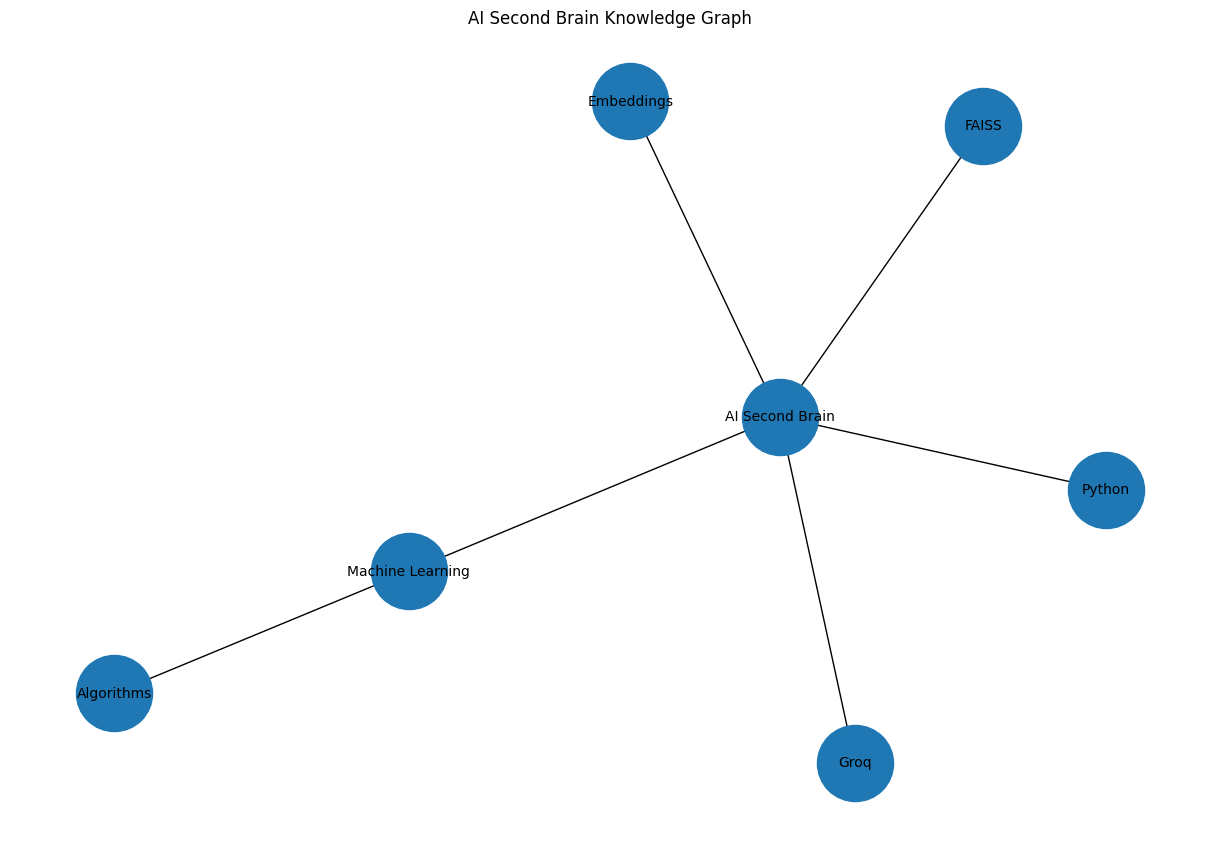

✅ Knowledge graph created successfully!


In [28]:
# ============================================
# AI SECOND BRAIN - STEP 18
# Knowledge Graph
# ============================================

import networkx as nx
import matplotlib.pyplot as plt

# Create knowledge graph
knowledge_graph = nx.Graph()

# Add nodes
knowledge_graph.add_node("AI Second Brain", type="Project")
knowledge_graph.add_node("Python", type="Technology")
knowledge_graph.add_node("Machine Learning", type="Topic")
knowledge_graph.add_node("Algorithms", type="Concept")
knowledge_graph.add_node("FAISS", type="Technology")
knowledge_graph.add_node("Embeddings", type="Concept")
knowledge_graph.add_node("Groq", type="Technology")

# Add relationships
knowledge_graph.add_edge(
    "AI Second Brain",
    "Python",
    relationship="USES"
)

knowledge_graph.add_edge(
    "AI Second Brain",
    "Machine Learning",
    relationship="RELATED_TO"
)

knowledge_graph.add_edge(
    "Machine Learning",
    "Algorithms",
    relationship="CONTAINS"
)

knowledge_graph.add_edge(
    "AI Second Brain",
    "FAISS",
    relationship="USES"
)

knowledge_graph.add_edge(
    "AI Second Brain",
    "Embeddings",
    relationship="USES"
)

knowledge_graph.add_edge(
    "AI Second Brain",
    "Groq",
    relationship="USES"
)

# Draw graph
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(
    knowledge_graph,
    seed=42
)

nx.draw(
    knowledge_graph,
    pos,
    with_labels=True,
    node_size=3000,
    font_size=10
)

plt.title("AI Second Brain Knowledge Graph")

plt.show()

print("✅ Knowledge graph created successfully!")

In [30]:
# ============================================
# AI SECOND BRAIN - STEP 19
# Connection Discovery
# ============================================

def find_connections(new_text, existing_chunks, top_k=3):

    # Convert new information into embedding
    new_embedding = embedding_model.encode(
        [new_text],
        convert_to_numpy=True
    ).astype("float32")

    # Convert existing knowledge into embeddings
    existing_embeddings = embedding_model.encode(
        existing_chunks,
        convert_to_numpy=True,
        show_progress_bar=False
    ).astype("float32")

    # Create temporary FAISS index
    temp_index = faiss.IndexFlatL2(
        existing_embeddings.shape[1]
    )

    temp_index.add(existing_embeddings)

    # Search for related knowledge
    distances, indices = temp_index.search(
        new_embedding,
        top_k
    )

    connections = []

    for position, index in enumerate(indices[0]):

        connections.append({
            "existing_knowledge": existing_chunks[index],
            "similarity_distance": float(
                distances[0][position]
            )
        })

    return connections


print("✅ Connection discovery function created!")

✅ Connection discovery function created!


In [31]:
# ============================================
# AI SECOND BRAIN - STEP 20
# Test Connection Discovery
# ============================================

new_information = """
Decision trees are machine learning algorithms
that can be used for classification and regression.
They make predictions by splitting data based on
different features.
"""

connections = find_connections(
    new_information,
    chunks,
    top_k=3
)

print("🔗 RELATED KNOWLEDGE\n")

for i, connection in enumerate(connections, start=1):

    print(f"--- Connection {i} ---")

    print(connection["existing_knowledge"])

    print(
        "\nDistance:",
        connection["similarity_distance"]
    )

    print()

🔗 RELATED KNOWLEDGE

--- Connection 1 ---
major	categories,	as
we	explained	before.
-
								
Supervised	learning
-
								
Unsupervised	learning
-
								
Semi-supervised	learning
-
								
Reinforcement	learning
	
Supervised	Learning
In	this	type	of	machine-learning	system,	the	data	that	you	feed	into	the
algorithm,	with	the	desired	solution,	are	referred	to	as	“labels.”
-
								
Supervised	learning	groups	together	a	tasks	of	classification.	The	above
program	is	a	good	example	of	this	because	it's	been	trained	with	many	emails
at	the	same	time	as	their	class.
	
	
Another	example	is	to	predict	a	numeric	value	like	the	price	of	a	flat,	given	a	set
of	features	(location,	number	of	rooms,	facilities)	called	predictors;	this	type	of
task	is	called	regression.
You	should	keep	in	mind	that	some	regression	algorithms	can	be	used

Distance: 0.7866546511650085

--- Connection 2 ---
es	of	Systems	of	Machine	Learning
	
There	are	different	types	of	machine-learning	systems.	We	can	divide	th

In [32]:
# ============================================
# AI SECOND BRAIN - STEP 21
# AI Connection Insight
# ============================================

def explain_connection(new_document, connections):

    related_text = "\n\n".join(
        [
            item["existing_knowledge"]
            for item in connections
        ]
    )

    prompt = f"""
You are an AI Second Brain insight agent.

A new piece of information has been added
to the user's knowledge base.

NEW INFORMATION:
{new_document}

EXISTING RELATED KNOWLEDGE:
{related_text}

Find meaningful connections between the new
information and the existing knowledge.

Return:

1. Connection
2. Why they are related
3. Why this connection may be useful

Do not invent unsupported connections.
Use only the information provided.
"""

    response = client.chat.completions.create(
        model="openai/gpt-oss-120b",
        messages=[
            {
                "role": "system",
                "content": "You are a personal knowledge insight assistant."
            },
            {
                "role": "user",
                "content": prompt
            }
        ],
        temperature=0.2
    )

    return response.choices[0].message.content


print("✅ AI connection insight function created!")

✅ AI connection insight function created!


In [33]:
# ============================================
# AI SECOND BRAIN - STEP 22
# Test AI Connection Insight
# ============================================

insight = explain_connection(
    new_information,
    connections
)

print("\n🧠 SECOND BRAIN INSIGHT\n")
print(insight)


🧠 SECOND BRAIN INSIGHT

**1. Connection**  
Decision trees are a *supervised‑learning* algorithm that can be applied to both **classification** and **regression** tasks, the same two task types described in the existing knowledge base.

**2. Why they are related**  
- The existing knowledge groups supervised learning into **classification** (e.g., email‑spam detection) and **regression** (e.g., predicting the price of a flat from features).  
- The new information states that decision trees “can be used for classification and regression” and that they “make predictions by splitting data based on different features.”  
- Splitting on features is precisely the mechanism by which supervised models learn from labeled data, matching the definition of supervised learning in the existing notes.

**3. Why this connection may be useful**  
- **Concrete example:** Adding decision trees to the knowledge base gives the user a concrete, widely‑used algorithm that embodies the abstract categories o

In [34]:
# ============================================
# AI SECOND BRAIN - STEP 23
# Gradio Interface
# ============================================

import gradio as gr


def brain_interface(question):

    if not question or not question.strip():
        return "Please enter a question."

    try:

        # Search uploaded documents
        results = search_brain_with_sources(
            question,
            top_k=5
        )

        if not results:
            return "I don't have enough information in my current memory."

        # Prepare retrieved information
        context = "\n\n".join(
            [
                f"Source: {result['source']}\n"
                f"{result['text']}"
                for result in results
            ]
        )

        # Create AI prompt
        prompt = f"""
You are an AI Second Brain.

Answer the user's question using the information
retrieved from their uploaded Machine Learning
documents.

IMPORTANT RULES:
1. Use the retrieved documents as your primary source.
2. Do not invent information.
3. If the answer is not available, say:
   "I don't have enough information in my current memory."
4. Explain the answer clearly and simply.
5. Mention the source document when useful.

RETRIEVED KNOWLEDGE:
--------------------
{context}
--------------------

USER QUESTION:
{question}
"""

        # Ask Groq
        response = client.chat.completions.create(
            model="openai/gpt-oss-120b",
            messages=[
                {
                    "role": "system",
                    "content": "You are a personal knowledge assistant."
                },
                {
                    "role": "user",
                    "content": prompt
                }
            ],
            temperature=0.2
        )

        answer = response.choices[0].message.content

        # Collect unique sources
        sources = []
        for result in results:

            source = result["source"]

            if source not in sources:
                sources.append(source)

        source_text = "\n\n📄 SOURCES:\n"

        for source in sources:
            source_text += f"• {source}\n"

        return answer + source_text

    except Exception as e:

        return f"❌ Error:\n{str(e)}"


# Create Gradio interface
demo = gr.Interface(

    fn=brain_interface,

    inputs=gr.Textbox(
        label="🧠 Ask Your Second Brain",
        placeholder="Ask something about your Machine Learning documents...",
        lines=3
    ),

    outputs=gr.Textbox(
        label="🤖 Second Brain Answer",
        lines=15
    ),

    title="🧠 AI Second Brain",

    description=(
        "Ask questions about your uploaded "
        "Machine Learning documents."
    )
)


demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://89c858c262e2836603.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [35]:
# ============================================
# AI SECOND BRAIN - STEP 24
# Upload Documents from Gradio
# ============================================

import gradio as gr
from pypdf import PdfReader


def upload_documents(uploaded_files):

    global chunks
    global document_names
    global embeddings
    global memory_index

    if not uploaded_files:
        return "❌ Please upload at least one PDF."

    new_chunks = []
    new_document_names = []

    for file in uploaded_files:

        file_path = file.name

        print("📄 Processing:", file_path)

        reader = PdfReader(file_path)

        text = ""

        for page in reader.pages:

            page_text = page.extract_text()

            if page_text:
                text += page_text + "\n"

        file_chunks = create_chunks(text)

        new_chunks.extend(file_chunks)

        new_document_names.extend(
            [file_path.split("/")[-1]] * len(file_chunks)
        )

    # Add new knowledge
    chunks.extend(new_chunks)
    document_names.extend(new_document_names)

    # Recreate embeddings
    embeddings = embedding_model.encode(
        chunks,
        convert_to_numpy=True,
        show_progress_bar=True
    )

    # Recreate FAISS memory
    dimension = embeddings.shape[1]

    memory_index = faiss.IndexFlatL2(dimension)

    memory_index.add(
        np.array(embeddings).astype("float32")
    )

    return (
        f"✅ Documents added successfully!\n\n"
        f"📚 New chunks: {len(new_chunks)}\n"
        f"🧠 Total memories: {len(chunks)}\n"
        f"📄 Total documents: {len(set(document_names))}"
    )


# Upload interface
upload_demo = gr.Interface(

    fn=upload_documents,

    inputs=gr.File(
        label="📚 Upload Machine Learning PDFs",
        file_count="multiple",
        file_types=[".pdf"]
    ),

    outputs=gr.Textbox(
        label="📊 Memory Status",
        lines=6
    ),

    title="📚 Add Knowledge to AI Second Brain",

    description=(
        "Upload one or more Machine Learning PDF documents "
        "to add them to your Second Brain memory."
    )
)

upload_demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d52e6603bc27a4b2e4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [36]:
# ============================================
# AI SECOND BRAIN - STEP 25
# Combined Upload + Ask Interface
# ============================================

import gradio as gr


def add_documents(uploaded_files):

    global chunks
    global document_names
    global embeddings
    global memory_index

    if not uploaded_files:
        return "❌ Please upload at least one PDF."

    new_chunks = []
    new_document_names = []

    for file in uploaded_files:

        file_path = file.name

        reader = PdfReader(file_path)

        text = ""

        for page in reader.pages:

            page_text = page.extract_text()

            if page_text:
                text += page_text + "\n"

        file_chunks = create_chunks(text)

        new_chunks.extend(file_chunks)

        new_document_names.extend(
            [file_path.split("/")[-1] for _ in file_chunks]
        )

    # Add new knowledge
    chunks.extend(new_chunks)
    document_names.extend(new_document_names)

    # Recreate embeddings
    embeddings = embedding_model.encode(
        chunks,
        convert_to_numpy=True,
        show_progress_bar=True
    )

    # Recreate FAISS memory
    dimension = embeddings.shape[1]

    memory_index = faiss.IndexFlatL2(dimension)

    memory_index.add(
        np.array(embeddings).astype("float32")
    )

    return (
        f"✅ Knowledge added successfully!\n\n"
        f"📚 New chunks: {len(new_chunks)}\n"
        f"🧠 Total memories: {len(chunks)}\n"
        f"📄 Total documents: {len(set(document_names))}"
    )


def ask_second_brain(question):

    if not question or not question.strip():

        return (
            "Please enter a question.",
            ""
        )

    try:

        # Search memory
        results = search_brain_with_sources(
            question,
            top_k=5
        )

        if not results:

            return (
                "I don't have enough information in my current memory.",
                ""
            )

        # Build context
        context = "\n\n".join(
            [
                f"Source: {result['source']}\n"
                f"{result['text']}"
                for result in results
            ]
        )

        # AI prompt
        prompt = f"""
You are an AI Second Brain.

Answer the user's question using the retrieved
knowledge from their uploaded Machine Learning documents.

IMPORTANT RULES:

1. Use the retrieved documents as your primary source.
2. Do not invent information.
3. If the answer is not available, say:
"I don't have enough information in my current memory."
4. Explain the answer in simple and clear language.
5. Give examples when the documents contain examples.
6. Mention the source documents used.

RETRIEVED KNOWLEDGE:
--------------------
{context}
--------------------

USER QUESTION:
{question}
"""

        response = client.chat.completions.create(

            model="openai/gpt-oss-120b",

            messages=[
                {
                    "role": "system",
                    "content": "You are a personal knowledge assistant."
                },
                {
                    "role": "user",
                    "content": prompt
                }
            ],

            temperature=0.2
        )

        answer = response.choices[0].message.content

        # Get unique sources
        sources = []

        for result in results:

            source = result["source"]

            if source not in sources:
                sources.append(source)

        source_text = "\n".join(
            [f"📄 {source}" for source in sources]
        )

        return answer, source_text

    except Exception as e:

        return (
            f"❌ Error:\n{str(e)}",
            ""
        )


# ============================================
# GRADIO UI
# ============================================

with gr.Blocks(title="AI Second Brain") as demo:

    gr.Markdown(
        """
        # 🧠 AI Second Brain

        ### Your Personal Machine Learning Knowledge Assistant

        Upload your ML documents, then ask questions
        using your stored knowledge.
        """
    )

    gr.Markdown("## 📚 1. Add Knowledge")

    upload = gr.File(
        label="Upload Machine Learning PDFs",
        file_count="multiple",
        file_types=[".pdf"]
    )

    upload_button = gr.Button(
        "➕ Add Documents"
    )

    upload_status = gr.Textbox(
        label="Memory Status",
        lines=5
    )

    upload_button.click(
        fn=add_documents,
        inputs=upload,
        outputs=upload_status
    )

    gr.Markdown("## 🧠 2. Ask Your Second Brain")

    question = gr.Textbox(
        label="Your Question",
        placeholder="Example: Explain decision tree in simple words...",
        lines=3
    )

    ask_button = gr.Button(
        "🤖 Ask Second Brain"
    )

    answer = gr.Textbox(
        label="AI Answer",
        lines=12
    )

    sources = gr.Textbox(
        label="📄 Sources Used",
        lines=5
    )

    ask_button.click(
        fn=ask_second_brain,
        inputs=question,
        outputs=[answer, sources]
    )


demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f9c74045dab1723729.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [37]:
# ============================================
# AI SECOND BRAIN - STEP 26
# Connection Discovery UI
# ============================================

def connection_interface(new_information):

    if not new_information or not new_information.strip():
        return "Please enter some new information."

    try:

        # Find related knowledge
        connections = find_connections(
            new_information,
            chunks,
            top_k=3
        )

        if not connections:
            return "No related knowledge found."

        # Ask AI to explain the connections
        insight = explain_connection(
            new_information,
            connections
        )

        # Show related sources/knowledge
        related_text = "\n\n🔗 RELATED KNOWLEDGE\n\n"

        for i, connection in enumerate(connections, start=1):

            related_text += (
                f"--- Connection {i} ---\n"
                f"{connection['existing_knowledge']}\n\n"
                f"Distance: "
                f"{connection['similarity_distance']:.4f}\n\n"
            )

        return (
            "🧠 AI CONNECTION INSIGHT\n\n"
            + insight
            + related_text
        )

    except Exception as e:

        return f"❌ Error:\n{str(e)}"


# ============================================
# GRADIO CONNECTION INTERFACE
# ============================================

with gr.Blocks(title="AI Second Brain - Connections") as connection_demo:

    gr.Markdown(
        """
        # 🔗 AI Second Brain — Connection Discovery

        Enter new Machine Learning knowledge and let
        your Second Brain discover related information
        from your existing documents.
        """
    )

    new_information = gr.Textbox(
        label="🆕 New Knowledge",
        placeholder=(
            "Example: Decision trees can be used "
            "for classification and regression."
        ),
        lines=6
    )

    connection_button = gr.Button(
        "🔗 Find Connections"
    )

    connection_output = gr.Textbox(
        label="🧠 Connection Insights",
        lines=20
    )

    connection_button.click(
        fn=connection_interface,
        inputs=new_information,
        outputs=connection_output
    )


connection_demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ea070300d5dffa8eec.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [38]:
# ============================================
# AI SECOND BRAIN - STEP 27
# Automatic Knowledge Graph
# ============================================

import json
import re


def extract_knowledge_graph(text):

    prompt = f"""
You are a knowledge graph extraction system.

Read the following Machine Learning text.

Extract important concepts and relationships.

Return ONLY valid JSON in this format:

{{
    "nodes": [
        {{
            "name": "Decision Tree",
            "type": "Algorithm"
        }}
    ],
    "relationships": [
        {{
            "source": "Decision Tree",
            "target": "Classification",
            "relationship": "USED_FOR"
        }}
    ]
}}

Rules:
1. Extract only information supported by the text.
2. Do not invent concepts.
3. Keep node names short.
4. Avoid duplicate nodes.
5. Extract important relationships only.

TEXT:
{text[:12000]}
"""

    response = client.chat.completions.create(

        model="openai/gpt-oss-120b",

        messages=[
            {
                "role": "system",
                "content": "You extract structured knowledge graphs."
            },
            {
                "role": "user",
                "content": prompt
            }
        ],

        temperature=0
    )

    result = response.choices[0].message.content

    # Remove possible markdown code fences
    result = re.sub(
        r"```json|```",
        "",
        result
    ).strip()

    return json.loads(result)


print("✅ Knowledge graph extraction function created!")

✅ Knowledge graph extraction function created!


In [39]:
# ============================================
# TEST AUTOMATIC KNOWLEDGE GRAPH
# ============================================

sample_text = chunks[0]

graph_data = extract_knowledge_graph(
    sample_text
)

print("🧠 NODES\n")

for node in graph_data["nodes"]:

    print(
        "•",
        node["name"],
        "| Type:",
        node["type"]
    )


print("\n🔗 RELATIONSHIPS\n")

for relationship in graph_data["relationships"]:

    print(
        "•",
        relationship["source"],
        "→",
        relationship["relationship"],
        "→",
        relationship["target"]
    )

🧠 NODES

• Machine Learning | Type: Field
• Algorithm | Type: Concept
• Python | Type: Language
• Guide | Type: Document
• Rudolph Russell | Type: Person
• Copyright | Type: Legal
• 2018 | Type: Year

🔗 RELATIONSHIPS

• Guide → COVERS → Machine Learning
• Guide → COVERS → Algorithm
• Guide → USES → Python
• Algorithm → FOR → Machine Learning
• Rudolph Russell → AUTHOR_OF → Guide
• Copyright → YEAR → 2018


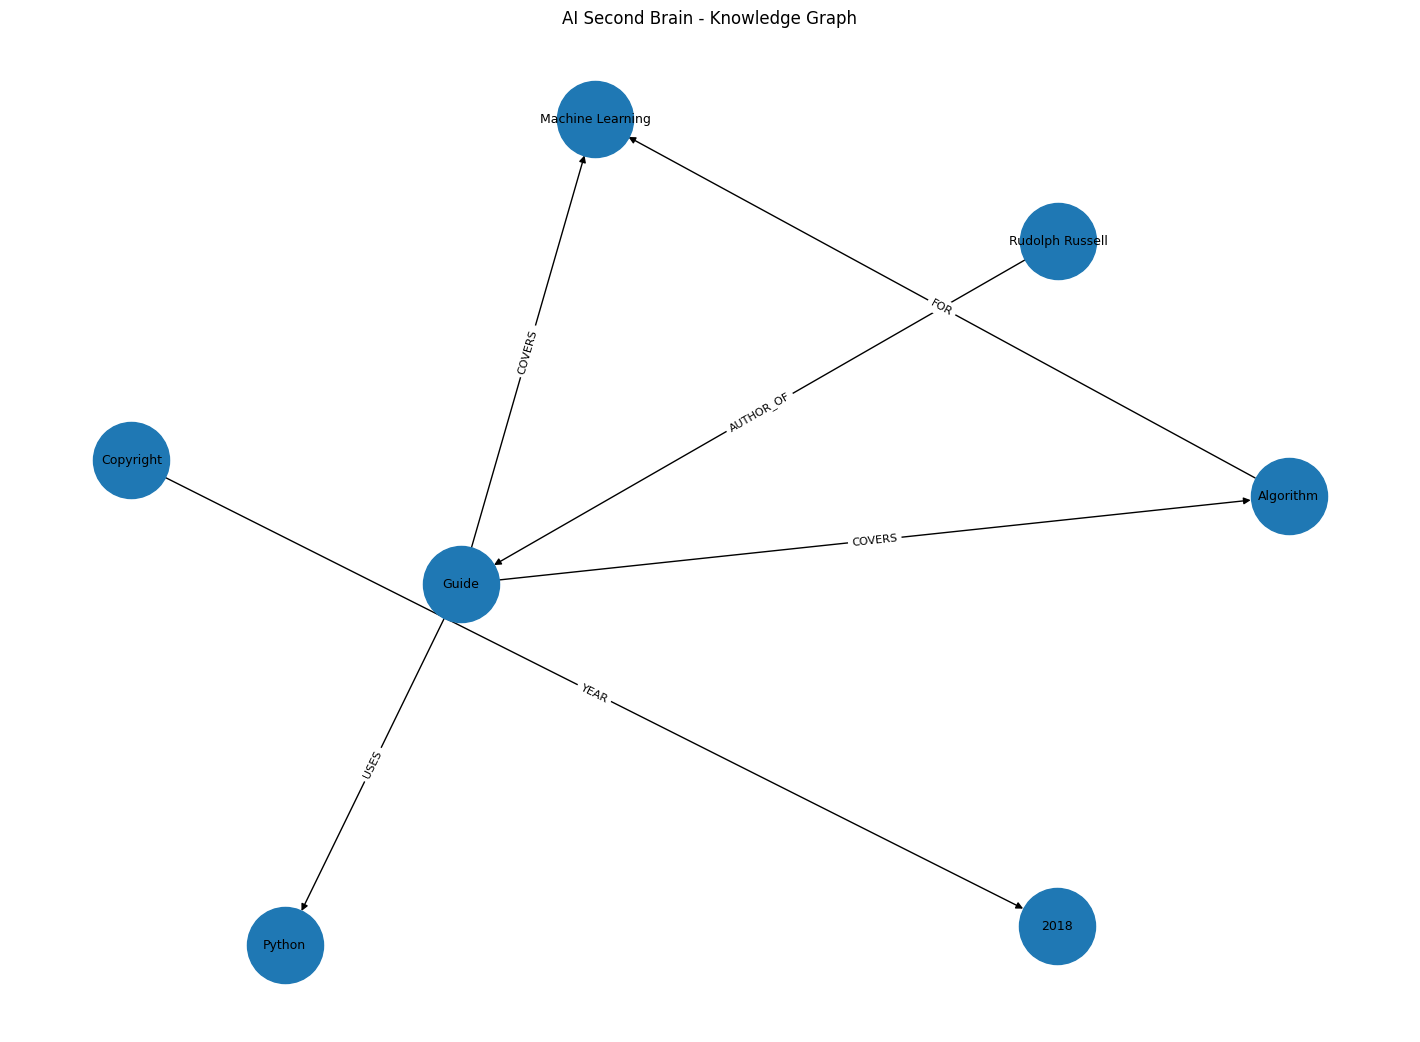

✅ Automatic knowledge graph created!
🧠 Nodes: 7
🔗 Relationships: 6


In [40]:
# ============================================
# AI SECOND BRAIN - STEP 28
# Visualize Automatic Knowledge Graph
# ============================================

import networkx as nx
import matplotlib.pyplot as plt


def build_knowledge_graph(graph_data):

    graph = nx.DiGraph()

    # Add nodes
    for node in graph_data["nodes"]:

        graph.add_node(
            node["name"],
            type=node["type"]
        )

    # Add relationships
    for relationship in graph_data["relationships"]:

        graph.add_edge(
            relationship["source"],
            relationship["target"],
            relationship=relationship["relationship"]
        )

    return graph


def visualize_knowledge_graph(graph_data):

    graph = build_knowledge_graph(graph_data)

    plt.figure(figsize=(14, 10))

    pos = nx.spring_layout(
        graph,
        seed=42,
        k=2
    )

    nx.draw(
        graph,
        pos,
        with_labels=True,
        node_size=3000,
        font_size=9,
        arrows=True
    )

    # Draw relationship labels
    edge_labels = nx.get_edge_attributes(
        graph,
        "relationship"
    )

    nx.draw_networkx_edge_labels(
        graph,
        pos,
        edge_labels=edge_labels,
        font_size=8
    )

    plt.title(
        "AI Second Brain - Knowledge Graph"
    )

    plt.show()

    return graph


knowledge_graph = visualize_knowledge_graph(
    graph_data
)

print("✅ Automatic knowledge graph created!")
print("🧠 Nodes:", knowledge_graph.number_of_nodes())
print("🔗 Relationships:", knowledge_graph.number_of_edges())

In [42]:

chunks[0]

'Machine\tLearning\n\t\nStep-by-Step\tGuide\tTo\tImplement\nMachine\tLearning\tAlgorithms\twith\tPython\n\t\n\t\n\t\n\t\n\t\n\t\n\t\n\t\nAuthor\nRudolph\tRussell\n©\nCopyright\t2018\t-\tAll\trights\treserved.\n\t\nIf\tyou\twould\tlike\tto\tshare\tthis\tbook\twith\tanother\tperson,\tplease\tpurchase\tan\nadditional\tcopy\tfor\teach\trecipient.\tThank\tyou\tfor\trespecting\tthe\thard\twork\tof\nthis\tauthor.\tOtherwise,\tthe\ttransmission,\tduplication\tor\treproduction\tof\tany\tof\nthe\tfollowing\twork\tincluding\tspecific\tinformation\twill\tbe\tconsidered\tan\tillegal\nact\tirrespective\tof\tif\tit\tis\tdone\telectronically\tor\tin\tprint.\tThis\textends\tto\tcreating\na\tsecondary\tor\ttertiary\tcopy\tof\tthe\twork\tor\ta\trecorded\tcopy\tand\tis\tonly\tallowed\nwith\tan\texpress\twritten\tconsent\tfrom\tthe\tPublisher.\tAll\tadditional\tright\treserved.\nTable\tof\tContents\n\t\nCHAPTER\t1\nINTRODUCTION\tTO\tMACHINE\tLEARNING'

In [46]:
# ============================================
# STEP 29 FIX - BATCH KNOWLEDGE GRAPH
# ============================================

def create_full_knowledge_graph():

    print("🧠 Analyzing your stored knowledge...")
    print("📚 Total chunks:", len(chunks))

    # Process chunks in small batches
    batch_size = 8

    all_nodes = {}
    all_relationships = []

    total_batches = (
        len(chunks) + batch_size - 1
    ) // batch_size

    for batch_number in range(
        total_batches
    ):

        start = batch_number * batch_size
        end = start + batch_size

        batch = chunks[start:end]

        batch_text = "\n\n".join(batch)

        print(
            f"\n🤖 Processing batch "
            f"{batch_number + 1}/{total_batches}..."
        )

        try:

            graph_data = extract_knowledge_graph(
                batch_text
            )

            # Store unique nodes
            for node in graph_data.get(
                "nodes",
                []
            ):

                node_name = node["name"]

                all_nodes[node_name] = node

            # Store relationships
            for relationship in graph_data.get(
                "relationships",
                []
            ):

                if relationship not in all_relationships:

                    all_relationships.append(
                        relationship
                    )

        except Exception as e:

            print(
                f"⚠️ Batch {batch_number + 1} skipped:"
            )

            print(str(e))

    final_graph_data = {
        "nodes": list(all_nodes.values()),
        "relationships": all_relationships
    }

    final_graph = build_knowledge_graph(
        final_graph_data
    )

    print("\n================================")
    print("✅ FULL KNOWLEDGE GRAPH CREATED")
    print("================================")

    print(
        "🧠 Nodes:",
        final_graph.number_of_nodes()
    )

    print(
        "🔗 Relationships:",
        final_graph.number_of_edges()
    )

    return final_graph_data, final_graph


print("✅ Batch knowledge graph function ready!")

✅ Batch knowledge graph function ready!


In [48]:
full_graph_data, full_knowledge_graph = (
    create_full_knowledge_graph()
)

print("\n✅ Full knowledge graph created successfully!")

🧠 Analyzing your stored knowledge...
📚 Total chunks: 204

🤖 Processing batch 1/26...

🤖 Processing batch 2/26...

🤖 Processing batch 3/26...

🤖 Processing batch 4/26...

🤖 Processing batch 5/26...

🤖 Processing batch 6/26...

🤖 Processing batch 7/26...

🤖 Processing batch 8/26...

🤖 Processing batch 9/26...

🤖 Processing batch 10/26...

🤖 Processing batch 11/26...

🤖 Processing batch 12/26...

🤖 Processing batch 13/26...

🤖 Processing batch 14/26...

🤖 Processing batch 15/26...

🤖 Processing batch 16/26...

🤖 Processing batch 17/26...

🤖 Processing batch 18/26...

🤖 Processing batch 19/26...

🤖 Processing batch 20/26...

🤖 Processing batch 21/26...

🤖 Processing batch 22/26...

🤖 Processing batch 23/26...

🤖 Processing batch 24/26...

🤖 Processing batch 25/26...

🤖 Processing batch 26/26...

✅ FULL KNOWLEDGE GRAPH CREATED
🧠 Nodes: 443
🔗 Relationships: 475

✅ Full knowledge graph created successfully!


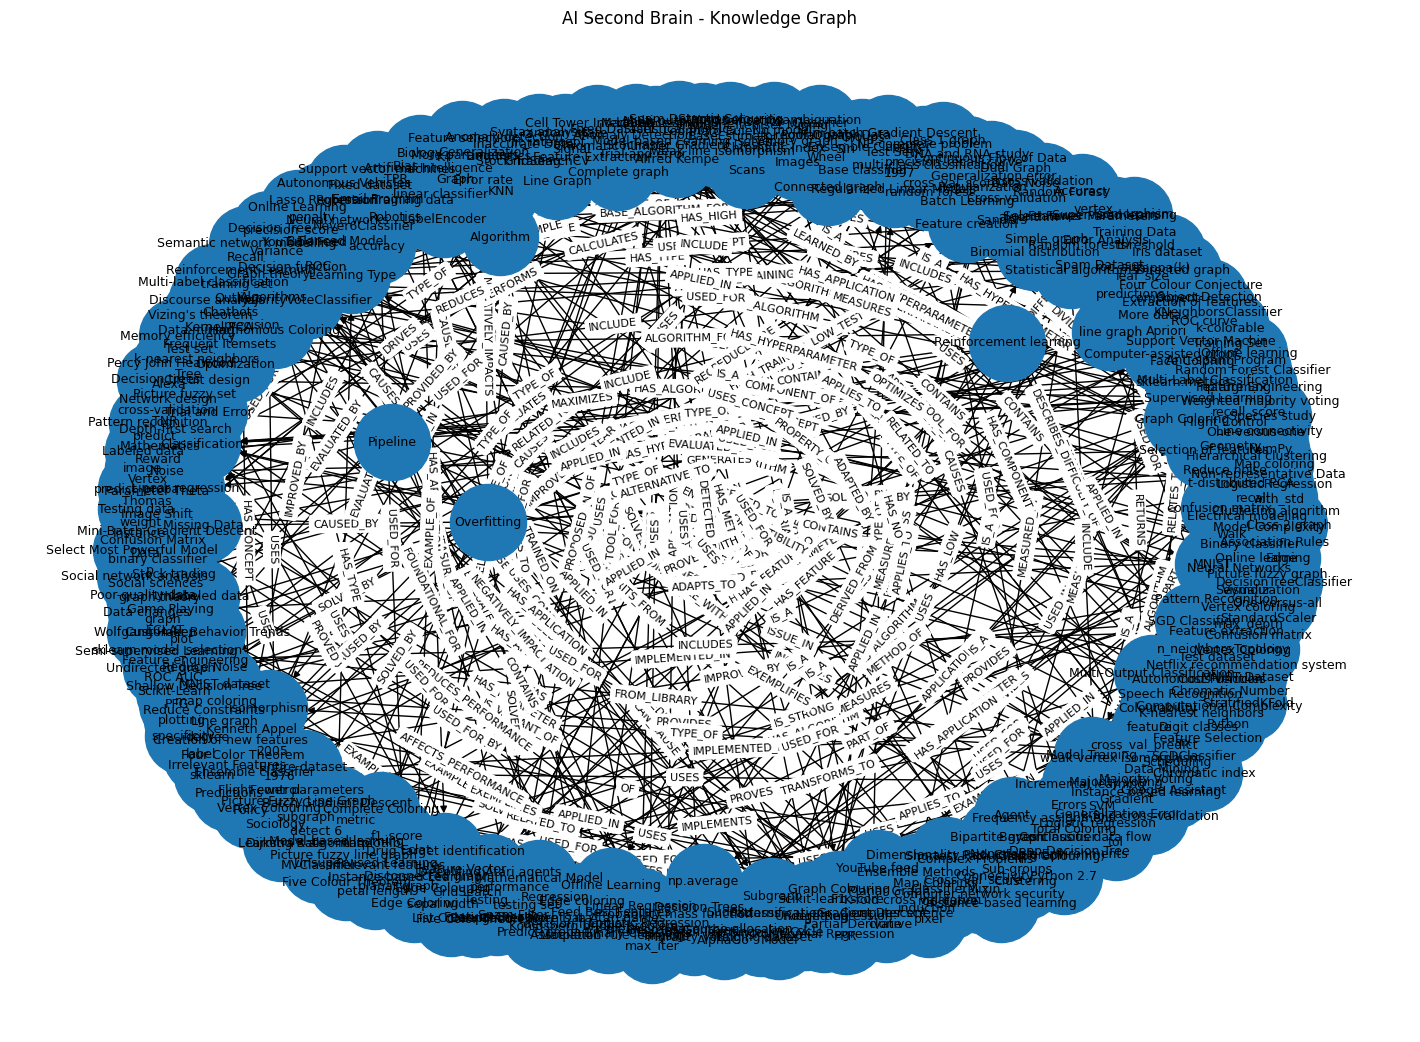

✅ Full knowledge graph visualization completed!


In [49]:
# ============================================
# AI SECOND BRAIN - STEP 30
# Visualize Full Knowledge Graph
# ============================================

visualize_knowledge_graph(
    full_graph_data
)

print("✅ Full knowledge graph visualization completed!")

In [50]:
# ============================================
# AI SECOND BRAIN - STEP 31
# Knowledge Graph Search
# ============================================

def search_knowledge_graph(topic):

    if not topic or not topic.strip():
        return "Please enter a topic."

    topic = topic.strip().lower()

    matches = []

    # Find matching nodes
    for node in full_knowledge_graph.nodes:

        if topic in node.lower():

            matches.append(node)

    if not matches:

        return (
            f"❌ No graph node found for: {topic}\n\n"
            "Try a topic such as:\n"
            "• Machine Learning\n"
            "• Decision Tree\n"
            "• Classification\n"
            "• Regression\n"
            "• Random Forest"
        )

    output = ""

    for node in matches:

        output += (
            f"🧠 NODE: {node}\n"
        )

        node_type = (
            full_knowledge_graph
            .nodes[node]
            .get("type", "Unknown")
        )

        output += (
            f"📌 Type: {node_type}\n\n"
        )

        # Connections from this node
        neighbors = list(
            full_knowledge_graph
            .neighbors(node)
        )

        if neighbors:

            output += "🔗 CONNECTED KNOWLEDGE:\n"

            for neighbor in neighbors:

                relationship = (
                    full_knowledge_graph
                    .edges[node, neighbor]
                    .get(
                        "relationship",
                        "RELATED_TO"
                    )
                )

                output += (
                    f"  {node} "
                    f"--[{relationship}]--> "
                    f"{neighbor}\n"
                )

        else:

            output += (
                "🔗 No direct connections found.\n"
            )

        output += "\n" + "=" * 50 + "\n\n"

    return output


print("✅ Knowledge Graph search ready!")

✅ Knowledge Graph search ready!


In [51]:
result = search_knowledge_graph(
    "Decision Tree"
)

print(result)

🧠 NODE: Decision trees
📌 Type: Algorithm

🔗 No direct connections found.


🧠 NODE: Decision Tree
📌 Type: Algorithm

🔗 CONNECTED KNOWLEDGE:
  Decision Tree --[BASE_ALGORITHM_FOR]--> Random Forest
  Decision Tree --[COMPONENT_OF]--> MajorityVoteClassifier
  Decision Tree --[EVALUATED_BY]--> ROC AUC
  Decision Tree --[EVALUATED_USING]--> cross-validation
  Decision Tree --[USED_FOR]--> Classification
  Decision Tree --[USED_FOR]--> Model


🧠 NODE: Decision Trees
📌 Type: Algorithm

🔗 No direct connections found.


🧠 NODE: Shallow Decision Tree
📌 Type: Model

🔗 CONNECTED KNOWLEDGE:
  Shallow Decision Tree --[EXEMPLIFIES]--> Underfitting


🧠 NODE: Deep Decision Tree
📌 Type: Model

🔗 CONNECTED KNOWLEDGE:
  Deep Decision Tree --[EXEMPLIFIES]--> Overfitting





In [53]:
# ============================================
# AI SECOND BRAIN - STEP 32
# Natural Language Graph Questions
# ============================================

def ask_graph(question):

    if not question or not question.strip():

        return "Please enter a question."

    try:

        # Find relevant graph nodes
        relevant_nodes = []

        question_lower = question.lower()

        for node in full_knowledge_graph.nodes:

            node_words = node.lower().split()

            if any(
                word in question_lower
                for word in node_words
                if len(word) > 3
            ):

                relevant_nodes.append(node)

        # If nothing matches, search memory
        if not relevant_nodes:

            return (
                "I could not find a matching concept "
                "in the knowledge graph."
            )

        # Build graph context
        graph_context = ""

        for node in relevant_nodes[:8]:

            node_type = (
                full_knowledge_graph
                .nodes[node]
                .get("type", "Unknown")
            )

            graph_context += (
                f"\nNode: {node}\n"
                f"Type: {node_type}\n"
            )

            neighbors = list(
                full_knowledge_graph
                .neighbors(node)
            )

            for neighbor in neighbors:

                relationship = (
                    full_knowledge_graph
                    .edges[node, neighbor]
                    .get(
                        "relationship",
                        "RELATED_TO"
                    )
                )

                graph_context += (
                    f"Relationship: "
                    f"{node} "
                    f"--[{relationship}]--> "
                    f"{neighbor}\n"
                )

        # Ask Groq to explain the graph
        prompt = f"""
You are the Knowledge Graph reasoning component
of an AI Second Brain.

Answer the user's question using ONLY the
knowledge graph information below.

USER QUESTION:
{question}

KNOWLEDGE GRAPH:
{graph_context}

Rules:
1. Do not invent relationships.
2. Explain the relationships clearly.
3. If the graph does not contain enough information,
say that clearly.
4. Use simple language.
"""

        response = client.chat.completions.create(

            model="openai/gpt-oss-120b",

            messages=[
                {
                    "role": "system",
                    "content": (
                        "You explain knowledge graph "
                        "relationships accurately."
                    )
                },
                {
                    "role": "user",
                    "content": prompt
                }
            ],

            temperature=0.2
        )

        return response.choices[0].message.content

    except Exception as e:

        return f"❌ Error:\n{str(e)}"


print("✅ Natural language graph reasoning ready!")

✅ Natural language graph reasoning ready!


In [54]:
question = input(
    "🔗 Ask your Knowledge Graph: "
)

answer = ask_graph(question)

print("\n🧠 GRAPH ANSWER\n")
print(answer)

🔗 Ask your Knowledge Graph: How is Decision Tree related to Random Forest?

🧠 GRAPH ANSWER

**Decision Tree → Random Forest**

- The knowledge graph states that **Decision Tree** has the relationship **BASE_ALGORITHM_FOR** → **Random Forest**.  
- This means a Decision Tree is the fundamental building block that Random Forest uses.  

In simple terms, a Random Forest is created by combining many Decision Trees (an ensemble of them) to make a stronger model for tasks like classification. The graph does not provide any other specific details about how they interact, but the **BASE_ALGORITHM_FOR** link clearly shows that Decision Trees are the core algorithms that Random Forests are built from.


In [55]:
# ============================================
# AI SECOND BRAIN - STEP 33
# Combined Memory + Knowledge Graph
# ============================================

def ask_complete_brain(question):

    if not question or not question.strip():

        return "Please enter a question."

    try:

        # ========================================
        # 1. SEARCH DOCUMENT MEMORY
        # ========================================

        memory_results = search_brain_with_sources(
            question,
            top_k=5
        )

        document_context = "\n\n".join(
            [
                f"Source: {result['source']}\n"
                f"{result['text']}"
                for result in memory_results
            ]
        )

        # ========================================
        # 2. SEARCH KNOWLEDGE GRAPH
        # ========================================

        question_lower = question.lower()

        relevant_nodes = []

        for node in full_knowledge_graph.nodes:

            node_words = node.lower().split()

            if any(
                word in question_lower
                for word in node_words
                if len(word) > 3
            ):

                relevant_nodes.append(node)

        graph_context = ""

        for node in relevant_nodes[:8]:

            neighbors = list(
                full_knowledge_graph
                .neighbors(node)
            )

            for neighbor in neighbors:

                relationship = (
                    full_knowledge_graph
                    .edges[node, neighbor]
                    .get(
                        "relationship",
                        "RELATED_TO"
                    )
                )

                graph_context += (
                    f"{node} "
                    f"--[{relationship}]--> "
                    f"{neighbor}\n"
                )

        # ========================================
        # 3. COMBINE BOTH SOURCES
        # ========================================

        prompt = f"""
You are an AI Second Brain.

Answer the user's question using BOTH:

1. Document Memory
2. Knowledge Graph

DOCUMENT MEMORY:
----------------
{document_context}
----------------

KNOWLEDGE GRAPH:
----------------
{graph_context}
----------------

USER QUESTION:
{question}

IMPORTANT RULES:

1. Use the provided information as your primary source.
2. Do not invent facts or relationships.
3. Clearly explain the answer.
4. If information is missing, say so.
5. Use simple language.
6. When useful, mention the source document.
7. Distinguish information from the documents from
relationships found in the knowledge graph.
"""

        response = client.chat.completions.create(

            model="openai/gpt-oss-120b",

            messages=[
                {
                    "role": "system",
                    "content": (
                        "You are a personal knowledge "
                        "assistant using document memory "
                        "and a knowledge graph."
                    )
                },
                {
                    "role": "user",
                    "content": prompt
                }
            ],

            temperature=0.2
        )

        answer = response.choices[0].message.content

        # ========================================
        # 4. SHOW SOURCES
        # ========================================

        sources = []

        for result in memory_results:

            source = result["source"]

            if source not in sources:
                sources.append(source)

        if sources:

            answer += "\n\n📄 SOURCES:\n"

            for source in sources:

                answer += f"• {source}\n"

        return answer

    except Exception as e:

        return f"❌ Error:\n{str(e)}"


print(
    "✅ Complete Second Brain reasoning system ready!"
)

✅ Complete Second Brain reasoning system ready!


In [56]:
question = input(
    "🧠 Ask your Complete Second Brain: "
)

answer = ask_complete_brain(question)

print("\n🤖 SECOND BRAIN\n")
print(answer)

🧠 Ask your Complete Second Brain: Explain Decision Tree in simple words and tell me what other concepts are connected to it.

🤖 SECOND BRAIN

**Decision Tree – simple explanation**

A Decision Tree is a flow‑chart‑like model that makes decisions by asking a series of yes/no (or “greater‑than / less‑than”) questions about the input data.  
- Each **node** asks one question about a feature (e.g., “Is the house price > $300 k?”).  
- Depending on the answer, you follow the **branch** to the next node, and so on, until you reach a **leaf** that gives the final prediction (a class label for classification or a numeric value for regression).  

Because the tree mimics the way a human might reason step‑by‑step, it is easy to understand and visualize.

**What the documents say**

The provided documents describe *supervised learning* (e.g., classification and regression) but do **not** contain a direct description of Decision Trees. Therefore, the simple definition above is based on general kno

In [57]:
import gradio as gr

# ============================================
# ADD DOCUMENTS
# ============================================

def add_documents_complete(uploaded_files):

    global chunks
    global document_names
    global embeddings
    global memory_index

    if not uploaded_files:
        return "❌ Please upload at least one PDF."

    new_chunks = []
    new_document_names = []

    for file in uploaded_files:

        file_path = file.name

        print("📄 Processing:", file_path)

        reader = PdfReader(file_path)

        text = ""

        for page in reader.pages:

            page_text = page.extract_text()

            if page_text:
                text += page_text + "\n"

        file_chunks = create_chunks(text)

        new_chunks.extend(file_chunks)

        new_document_names.extend(
            [file_path.split("/")[-1] for _ in file_chunks]
        )

    chunks.extend(new_chunks)

    document_names.extend(new_document_names)

    # Rebuild embeddings
    embeddings = embedding_model.encode(
        chunks,
        convert_to_numpy=True,
        show_progress_bar=True
    )

    # Rebuild FAISS memory
    dimension = embeddings.shape[1]

    memory_index = faiss.IndexFlatL2(dimension)

    memory_index.add(
        np.array(embeddings).astype("float32")
    )

    return (
        "✅ Documents added successfully!\n\n"
        f"📚 New chunks: {len(new_chunks)}\n"
        f"🧠 Total memories: {len(chunks)}\n"
        f"📄 Total documents: {len(set(document_names))}"
    )


# ============================================
# ASK COMPLETE SECOND BRAIN
# ============================================

def ask_complete_brain_ui(question):

    if not question or not question.strip():

        return (
            "Please enter a question.",
            "",
            ""
        )

    try:

        # ====================================
        # DOCUMENT MEMORY
        # ====================================

        memory_results = search_brain_with_sources(
            question,
            top_k=5
        )

        document_context = "\n\n".join(
            [
                f"Source: {result['source']}\n"
                f"{result['text']}"
                for result in memory_results
            ]
        )

        # ====================================
        # KNOWLEDGE GRAPH
        # ====================================

        question_lower = question.lower()

        relevant_nodes = []

        for node in full_knowledge_graph.nodes:

            node_words = node.lower().split()

            if any(
                word in question_lower
                for word in node_words
                if len(word) > 3
            ):

                relevant_nodes.append(node)

        graph_context = ""

        for node in relevant_nodes[:8]:

            neighbors = list(
                full_knowledge_graph.neighbors(node)
            )

            for neighbor in neighbors:

                relationship = (
                    full_knowledge_graph
                    .edges[node, neighbor]
                    .get(
                        "relationship",
                        "RELATED_TO"
                    )
                )

                graph_context += (
                    f"{node} "
                    f"--[{relationship}]--> "
                    f"{neighbor}\n"
                )

        # ====================================
        # AI REASONING
        # ====================================

        prompt = f"""
You are an AI Second Brain.

Answer the user's question using BOTH:

1. Document Memory
2. Knowledge Graph

DOCUMENT MEMORY:
----------------
{document_context}
----------------

KNOWLEDGE GRAPH:
----------------
{graph_context}
----------------

USER QUESTION:
{question}

IMPORTANT RULES:

1. Use the provided information as your primary source.
2. Do not invent facts or relationships.
3. Explain the answer clearly.
4. Use simple language.
5. If information is missing, say so.
6. Distinguish document information from graph relationships.
7. Give examples when useful.
"""

        response = client.chat.completions.create(

            model="openai/gpt-oss-120b",

            messages=[
                {
                    "role": "system",
                    "content": (
                        "You are a personal AI Second Brain "
                        "that combines document memory "
                        "and knowledge graph reasoning."
                    )
                },
                {
                    "role": "user",
                    "content": prompt
                }
            ],

            temperature=0.2
        )

        answer = response.choices[0].message.content

        # ====================================
        # SOURCES
        # ====================================

        sources = []

        for result in memory_results:

            source = result["source"]

            if source not in sources:

                sources.append(source)

        source_text = ""

        if sources:

            source_text = "\n".join(
                [
                    f"📄 {source}"
                    for source in sources
                ]
            )

        # ====================================
        # GRAPH INFORMATION
        # ====================================

        if graph_context.strip():

            graph_text = (
                "🔗 GRAPH CONNECTIONS\n\n"
                + graph_context
            )

        else:

            graph_text = (
                "🔗 No matching knowledge graph "
                "connections were found."
            )

        return (
            answer,
            source_text,
            graph_text
        )

    except Exception as e:

        return (
            f"❌ Error:\n{str(e)}",
            "",
            ""
        )


# ============================================
# COMPLETE GRADIO APPLICATION
# ============================================

with gr.Blocks(
    title="AI Second Brain"
) as second_brain_app:

    gr.Markdown(
        """
        # 🧠 AI Second Brain

        ### Your Personal Machine Learning Knowledge Assistant

        Upload your knowledge → build memory → ask questions →
        discover relationships between concepts.
        """
    )

    # ========================================
    # DOCUMENT SECTION
    # ========================================

    gr.Markdown(
        "## 📚 1. Add Knowledge"
    )

    upload = gr.File(
        label="Upload Machine Learning PDFs",
        file_count="multiple",
        file_types=[".pdf"]
    )

    add_button = gr.Button(
        "➕ Add Documents"
    )

    upload_status = gr.Textbox(
        label="🧠 Memory Status",
        lines=5
    )

    add_button.click(
        fn=add_documents_complete,
        inputs=upload,
        outputs=upload_status
    )

    # ========================================
    # QUESTION SECTION
    # ========================================

    gr.Markdown(
        "## 💬 2. Ask Your Second Brain"
    )

    question = gr.Textbox(
        label="🧠 Your Question",
        placeholder=(
            "Example: Explain Decision Tree "
            "and tell me how it is related to "
            "Random Forest."
        ),
        lines=3
    )

    ask_button = gr.Button(
        "🤖 Ask Second Brain"
    )

    # ========================================
    # ANSWER
    # ========================================

    answer = gr.Textbox(
        label="🤖 AI Answer",
        lines=12
    )

    # ========================================
    # SOURCES
    # ========================================

    sources = gr.Textbox(
        label="📄 Documents Used",
        lines=5
    )

    # ========================================
    # GRAPH
    # ========================================

    graph_info = gr.Textbox(
        label="🔗 Knowledge Graph Connections",
        lines=8
    )

    ask_button.click(
        fn=ask_complete_brain_ui,
        inputs=question,
        outputs=[
            answer,
            sources,
            graph_info
        ]
    )


# ============================================
# LAUNCH
# ============================================

second_brain_app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e475c76ad99934ed10.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [58]:
# ============================================
# STEP 35 — SAVE SECOND BRAIN MEMORY
# ============================================

import os
import pickle
import faiss

memory_folder = "/content/second_brain_memory"

os.makedirs(
    memory_folder,
    exist_ok=True
)

# Save chunks and document names
with open(
    f"{memory_folder}/memory_data.pkl",
    "wb"
) as file:

    pickle.dump(
        {
            "chunks": chunks,
            "document_names": document_names
        },
        file
    )

# Save FAISS index
faiss.write_index(
    memory_index,
    f"{memory_folder}/faiss.index"
)

print("================================")
print("✅ SECOND BRAIN MEMORY SAVED")
print("================================")

print(
    "📚 Memories:",
    len(chunks)
)

print(
    "📄 Documents:",
    len(set(document_names))
)

print(
    "💾 Location:",
    memory_folder
)

✅ SECOND BRAIN MEMORY SAVED
📚 Memories: 304
📄 Documents: 3
💾 Location: /content/second_brain_memory


In [59]:
# ============================================
# STEP 35 — SAVE KNOWLEDGE GRAPH
# ============================================

import pickle

# Save the complete knowledge graph data
with open(
    f"{memory_folder}/knowledge_graph.pkl",
    "wb"
) as file:

    pickle.dump(
        full_graph_data,
        file
    )

print("================================")
print("✅ KNOWLEDGE GRAPH SAVED")
print("================================")

print(
    "🧠 Nodes:",
    full_knowledge_graph.number_of_nodes()
)

print(
    "🔗 Relationships:",
    full_knowledge_graph.number_of_edges()
)

print(
    "💾 Location:",
    f"{memory_folder}/knowledge_graph.pkl"
)

✅ KNOWLEDGE GRAPH SAVED
🧠 Nodes: 443
🔗 Relationships: 475
💾 Location: /content/second_brain_memory/knowledge_graph.pkl


In [60]:
# ============================================
# STEP 35 — RESTORE SECOND BRAIN MEMORY
# ============================================

import os
import pickle
import faiss

def restore_second_brain():

    global chunks
    global document_names
    global memory_index
    global full_graph_data
    global full_knowledge_graph

    # ========================================
    # CHECK SAVED MEMORY
    # ========================================

    if not os.path.exists(memory_folder):

        return "❌ No saved Second Brain memory found."

    # ========================================
    # LOAD DOCUMENT MEMORY
    # ========================================

    with open(
        f"{memory_folder}/memory_data.pkl",
        "rb"
    ) as file:

        memory_data = pickle.load(file)

    chunks = memory_data["chunks"]

    document_names = memory_data["document_names"]

    # ========================================
    # LOAD FAISS MEMORY
    # ========================================

    memory_index = faiss.read_index(
        f"{memory_folder}/faiss.index"
    )

    # ========================================
    # LOAD KNOWLEDGE GRAPH
    # ========================================

    with open(
        f"{memory_folder}/knowledge_graph.pkl",
        "rb"
    ) as file:

        full_graph_data = pickle.load(file)

    # Rebuild NetworkX graph

    full_knowledge_graph = build_knowledge_graph(
        full_graph_data
    )

    # ========================================
    # SUCCESS
    # ========================================

    print("================================")
    print("✅ SECOND BRAIN MEMORY RESTORED")
    print("================================")

    print(
        "📚 Memories:",
        len(chunks)
    )

    print(
        "📄 Documents:",
        len(set(document_names))
    )

    print(
        "🧠 Graph Nodes:",
        full_knowledge_graph.number_of_nodes()
    )

    print(
        "🔗 Graph Relationships:",
        full_knowledge_graph.number_of_edges()
    )

    return "✅ Second Brain memory restored successfully!"


print("✅ Restore function created!")

✅ Restore function created!


In [61]:
restore_second_brain()

✅ SECOND BRAIN MEMORY RESTORED
📚 Memories: 304
📄 Documents: 3
🧠 Graph Nodes: 443
🔗 Graph Relationships: 475


'✅ Second Brain memory restored successfully!'

In [62]:
# ============================================
# STEP 36 — AUTOMATIC MEMORY RESTORE
# ============================================

def initialize_second_brain():

    print("🧠 Starting AI Second Brain...")
    print()

    if os.path.exists(memory_folder):

        try:

            result = restore_second_brain()

            print()
            print("🚀 Second Brain is ready!")

            return result

        except Exception as e:

            print(
                "⚠️ Saved memory found, "
                "but it could not be restored."
            )

            print("Error:", str(e))

            return "⚠️ Memory restore failed."

    else:

        print(
            "📭 No saved memory found."
        )

        print(
            "Upload documents to create "
            "your first memory."
        )

        return "📭 No saved memory yet."


print("✅ Automatic startup function created!")

✅ Automatic startup function created!


In [63]:
initialize_second_brain()

🧠 Starting AI Second Brain...

✅ SECOND BRAIN MEMORY RESTORED
📚 Memories: 304
📄 Documents: 3
🧠 Graph Nodes: 443
🔗 Graph Relationships: 475

🚀 Second Brain is ready!


'✅ Second Brain memory restored successfully!'

In [64]:
# ============================================
# STEP 36 — AUTO-SAVE NEW DOCUMENTS
# ============================================

def add_documents_and_save(uploaded_files):

    global chunks
    global document_names
    global embeddings
    global memory_index
    global full_graph_data
    global full_knowledge_graph

    if not uploaded_files:

        return "❌ Please upload at least one PDF."

    new_chunks = []
    new_document_names = []

    # ========================================
    # PROCESS DOCUMENTS
    # ========================================

    for file in uploaded_files:

        file_path = file.name

        print("📄 Processing:", file_path)

        reader = PdfReader(file_path)

        text = ""

        for page in reader.pages:

            page_text = page.extract_text()

            if page_text:

                text += page_text + "\n"

        file_chunks = create_chunks(text)

        new_chunks.extend(file_chunks)

        new_document_names.extend(
            [
                file_path.split("/")[-1]
                for _ in file_chunks
            ]
        )

    # ========================================
    # ADD TO MEMORY
    # ========================================

    chunks.extend(new_chunks)

    document_names.extend(
        new_document_names
    )

    # ========================================
    # REBUILD EMBEDDINGS
    # ========================================

    embeddings = embedding_model.encode(
        chunks,
        convert_to_numpy=True,
        show_progress_bar=True
    )

    # ========================================
    # REBUILD FAISS
    # ========================================

    dimension = embeddings.shape[1]

    memory_index = faiss.IndexFlatL2(
        dimension
    )

    memory_index.add(
        np.array(embeddings).astype("float32")
    )

    # ========================================
    # SAVE DOCUMENT MEMORY
    # ========================================

    with open(
        f"{memory_folder}/memory_data.pkl",
        "wb"
    ) as file:

        pickle.dump(
            {
                "chunks": chunks,
                "document_names": document_names
            },
            file
        )

    faiss.write_index(
        memory_index,
        f"{memory_folder}/faiss.index"
    )

    # ========================================
    # CREATE GRAPH FROM NEW KNOWLEDGE
    # ========================================

    if new_chunks:

        try:

            print(
                "\n🧠 Updating Knowledge Graph..."
            )

            batch_size = 8

            new_nodes = {}
            new_relationships = []

            for start in range(
                0,
                len(new_chunks),
                batch_size
            ):

                batch = new_chunks[
                    start:start + batch_size
                ]

                batch_text = "\n\n".join(batch)

                try:

                    graph_data = (
                        extract_knowledge_graph(
                            batch_text
                        )
                    )

                    for node in graph_data.get(
                        "nodes",
                        []
                    ):

                        new_nodes[
                            node["name"]
                        ] = node

                    for relationship in (
                        graph_data.get(
                            "relationships",
                            []
                        )
                    ):

                        if relationship not in new_relationships:

                            new_relationships.append(
                                relationship
                            )

                except Exception as e:

                    print(
                        "⚠️ Graph batch skipped:",
                        str(e)
                    )

            # Add new nodes
            for node_name, node in new_nodes.items():

                if node_name not in full_graph_data["nodes"]:

                    full_graph_data["nodes"].append(
                        node
                    )

            # Add new relationships
            for relationship in new_relationships:

                if relationship not in (
                    full_graph_data["relationships"]
                ):

                    full_graph_data[
                        "relationships"
                    ].append(
                        relationship
                    )

            # Rebuild graph
            full_knowledge_graph = (
                build_knowledge_graph(
                    full_graph_data
                )
            )

            # Save graph
            with open(
                f"{memory_folder}/knowledge_graph.pkl",
                "wb"
            ) as file:

                pickle.dump(
                    full_graph_data,
                    file
                )

        except Exception as e:

            print(
                "⚠️ Knowledge graph update failed:",
                str(e)
            )

    # ========================================
    # FINAL STATUS
    # ========================================

    return (
        "✅ Knowledge added and saved!\n\n"
        f"📚 New chunks: {len(new_chunks)}\n"
        f"🧠 Total memories: {len(chunks)}\n"
        f"📄 Total documents: "
        f"{len(set(document_names))}\n"
        f"🔗 Graph nodes: "
        f"{full_knowledge_graph.number_of_nodes()}\n"
        f"🔗 Graph relationships: "
        f"{full_knowledge_graph.number_of_edges()}"
    )


print(
    "✅ Automatic document saving system created!"
)

✅ Automatic document saving system created!


In [65]:
# ============================================
# STEP 36 — FINAL GRADIO INTERFACE
# ============================================

with gr.Blocks(
    title="AI Second Brain"
) as second_brain_app:

    gr.Markdown(
        """
        # 🧠 AI Second Brain

        ### Your Personal Machine Learning Knowledge Assistant

        📚 Upload knowledge → 🧠 Build memory →
        🔗 Discover connections → 🤖 Ask questions
        """
    )

    # ========================================
    # MEMORY STATUS
    # ========================================

    gr.Markdown(
        "## 🧠 Memory"
    )

    restore_button = gr.Button(
        "🔄 Restore Saved Memory"
    )

    restore_status = gr.Textbox(
        label="Memory Status",
        lines=6
    )

    restore_button.click(
        fn=restore_second_brain,
        inputs=[],
        outputs=restore_status
    )

    # ========================================
    # UPLOAD DOCUMENTS
    # ========================================

    gr.Markdown(
        "## 📚 Add New Knowledge"
    )

    upload = gr.File(
        label="Upload Machine Learning PDFs",
        file_count="multiple",
        file_types=[".pdf"]
    )

    add_button = gr.Button(
        "➕ Add & Save Documents"
    )

    upload_status = gr.Textbox(
        label="Upload Status",
        lines=8
    )

    add_button.click(
        fn=add_documents_and_save,
        inputs=upload,
        outputs=upload_status
    )

    # ========================================
    # ASK SECOND BRAIN
    # ========================================

    gr.Markdown(
        "## 💬 Ask Your Second Brain"
    )

    question = gr.Textbox(
        label="🧠 Your Question",
        placeholder=(
            "Example: Explain Decision Tree "
            "and tell me how it is related "
            "to Random Forest."
        ),
        lines=3
    )

    ask_button = gr.Button(
        "🤖 Ask Second Brain"
    )

    # ========================================
    # AI ANSWER
    # ========================================

    answer = gr.Textbox(
        label="🤖 AI Answer",
        lines=12
    )

    # ========================================
    # SOURCES
    # ========================================

    sources = gr.Textbox(
        label="📄 Documents Used",
        lines=5
    )

    # ========================================
    # KNOWLEDGE GRAPH
    # ========================================

    graph_info = gr.Textbox(
        label="🔗 Knowledge Graph Connections",
        lines=10
    )

    ask_button.click(
        fn=ask_complete_brain_ui,
        inputs=question,
        outputs=[
            answer,
            sources,
            graph_info
        ]
    )


# ============================================
# LAUNCH
# ============================================

second_brain_app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://59332711a1ac510a42.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [68]:
import matplotlib.pyplot as plt
import networkx as nx

def create_graph_image():

    if full_knowledge_graph.number_of_nodes() == 0:
        return None

    graph = full_knowledge_graph

    plt.figure(figsize=(16, 12))

    pos = nx.spring_layout(
        graph,
        seed=42,
        k=2
    )

    nx.draw_networkx_nodes(
        graph,
        pos,
        node_size=2500
    )

    nx.draw_networkx_edges(
        graph,
        pos,
        arrows=True,
        arrowsize=15
    )

    nx.draw_networkx_labels(
        graph,
        pos,
        font_size=9
    )

    edge_labels = nx.get_edge_attributes(
        graph,
        "relationship"
    )

    nx.draw_networkx_edge_labels(
        graph,
        pos,
        edge_labels=edge_labels,
        font_size=7
    )

    plt.title(
        "AI Second Brain Knowledge Graph",
        fontsize=16
    )

    plt.axis("off")

    graph_image_path = (
        "/content/second_brain_memory/"
        "knowledge_graph.png"
    )

    plt.savefig(
        graph_image_path,
        bbox_inches="tight"
    )

    plt.close()

    return graph_image_path


print("✅ Graph visualization function created!")

✅ Graph visualization function created!


In [69]:
graph_image = create_graph_image()

print("🧠 Graph image saved at:")
print(graph_image)

🧠 Graph image saved at:
/content/second_brain_memory/knowledge_graph.png


In [70]:
# ============================================
# STEP 37 — GRAPH VIEWER
# ============================================

def refresh_graph():

    try:

        graph_image = create_graph_image()

        if graph_image:

            return graph_image

        return None

    except Exception as e:

        print("❌ Graph error:", str(e))

        return None


with gr.Blocks(
    title="AI Second Brain - Knowledge Graph"
) as graph_app:

    gr.Markdown(
        """
        # 🧠 AI Second Brain — Knowledge Graph

        ### Explore the connections between your Machine Learning concepts.
        """
    )

    refresh_button = gr.Button(
        "🔄 Refresh Knowledge Graph"
    )

    graph_display = gr.Image(
        label="🔗 Knowledge Graph",
        type="filepath"
    )

    refresh_button.click(
        fn=refresh_graph,
        inputs=[],
        outputs=graph_display
    )


graph_app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://dc3164cdd791e7feaf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [71]:
# ============================================
# STEP 38 — TOPIC EXPLORER
# ============================================

def explore_topic(topic):

    if not topic or not topic.strip():

        return "❌ Please enter a topic."

    topic = topic.strip().lower()

    matches = []

    # Find matching nodes
    for node in full_knowledge_graph.nodes:

        if topic in node.lower():

            matches.append(node)

    if not matches:

        return (
            f"❌ No matching topic found for: {topic}\n\n"
            "Try:\n"
            "• Decision Tree\n"
            "• Random Forest\n"
            "• Classification\n"
            "• Regression\n"
            "• Machine Learning"
        )

    output = ""

    for node in matches:

        node_type = (
            full_knowledge_graph
            .nodes[node]
            .get(
                "type",
                "Unknown"
            )
        )

        output += (
            f"🧠 TOPIC: {node}\n"
            f"📌 TYPE: {node_type}\n\n"
        )

        neighbors = list(
            full_knowledge_graph
            .neighbors(node)
        )

        if neighbors:

            output += (
                "🔗 CONNECTED KNOWLEDGE:\n\n"
            )

            for neighbor in neighbors:

                relationship = (
                    full_knowledge_graph
                    .edges[node, neighbor]
                    .get(
                        "relationship",
                        "RELATED_TO"
                    )
                )

                output += (
                    f"  {node} "
                    f"--[{relationship}]--> "
                    f"{neighbor}\n"
                )

        else:

            output += (
                "🔗 No direct connections found.\n"
            )

        output += (
            "\n"
            + "=" * 55
            + "\n\n"
        )

    return output


print("✅ Topic Explorer created!")

✅ Topic Explorer created!


In [72]:
result = explore_topic(
    "Decision Tree"
)

print(result)

🧠 TOPIC: Decision trees
📌 TYPE: Algorithm

🔗 No direct connections found.


🧠 TOPIC: Decision Tree
📌 TYPE: Algorithm

🔗 CONNECTED KNOWLEDGE:

  Decision Tree --[BASE_ALGORITHM_FOR]--> Random Forest
  Decision Tree --[COMPONENT_OF]--> MajorityVoteClassifier
  Decision Tree --[EVALUATED_BY]--> ROC AUC
  Decision Tree --[EVALUATED_USING]--> cross-validation
  Decision Tree --[USED_FOR]--> Classification
  Decision Tree --[USED_FOR]--> Model
  Decision Tree --[USED_IN]--> Shallow Decision Tree
  Decision Tree --[USED_IN]--> Deep Decision Tree
  Decision Tree --[USED_IN]--> Balanced Model


🧠 TOPIC: Decision Trees
📌 TYPE: Algorithm

🔗 CONNECTED KNOWLEDGE:

  Decision Trees --[IS_A]--> Statistical Algorithms


🧠 TOPIC: Shallow Decision Tree
📌 TYPE: Model

🔗 CONNECTED KNOWLEDGE:

  Shallow Decision Tree --[EXEMPLIFIES]--> Underfitting
  Shallow Decision Tree --[TYPE_OF]--> Simple Model


🧠 TOPIC: Deep Decision Tree
📌 TYPE: Model

🔗 CONNECTED KNOWLEDGE:

  Deep Decision Tree --[EXEMPLIFIES]-->

In [73]:
# ============================================
# STEP 38 — TOPIC EXPLORER UI
# ============================================

with gr.Blocks(
    title="AI Second Brain - Topic Explorer"
) as topic_app:

    gr.Markdown(
        """
        # 🔍 AI Second Brain — Topic Explorer

        ### Explore concepts and their relationships
        in your Machine Learning knowledge graph.
        """
    )

    topic = gr.Textbox(
        label="🧠 Enter a Topic",
        placeholder=(
            "Example: Decision Tree"
        ),
        lines=2
    )

    explore_button = gr.Button(
        "🔍 Explore Topic"
    )

    topic_output = gr.Textbox(
        label="🔗 Topic Connections",
        lines=20
    )

    explore_button.click(
        fn=explore_topic,
        inputs=topic,
        outputs=topic_output
    )


topic_app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3ce441f8018149e4ff.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [74]:
# ============================================
# STEP 39 — CHAT HISTORY
# ============================================

chat_history = []


def ask_with_history(question):

    global chat_history

    if not question or not question.strip():

        return "Please enter a question."

    try:

        # ====================================
        # DOCUMENT MEMORY
        # ====================================

        memory_results = search_brain_with_sources(
            question,
            top_k=5
        )

        document_context = "\n\n".join(
            [
                f"Source: {result['source']}\n"
                f"{result['text']}"
                for result in memory_results
            ]
        )

        # ====================================
        # KNOWLEDGE GRAPH
        # ====================================

        question_lower = question.lower()

        relevant_nodes = []

        for node in full_knowledge_graph.nodes:

            node_words = node.lower().split()

            if any(
                word in question_lower
                for word in node_words
                if len(word) > 3
            ):

                relevant_nodes.append(node)

        graph_context = ""

        for node in relevant_nodes[:8]:

            for neighbor in (
                full_knowledge_graph
                .neighbors(node)
            ):

                relationship = (
                    full_knowledge_graph
                    .edges[node, neighbor]
                    .get(
                        "relationship",
                        "RELATED_TO"
                    )
                )

                graph_context += (
                    f"{node} "
                    f"--[{relationship}]--> "
                    f"{neighbor}\n"
                )

        # ====================================
        # PREVIOUS CHAT
        # ====================================

        previous_chat = ""

        for item in chat_history[-5:]:

            previous_chat += (
                f"User: {item['question']}\n"
                f"Assistant: {item['answer']}\n\n"
            )

        # ====================================
        # AI PROMPT
        # ====================================

        prompt = f"""
You are an AI Second Brain.

Use:

1. Document Memory
2. Knowledge Graph
3. Previous Conversation

DOCUMENT MEMORY:
----------------
{document_context}
----------------

KNOWLEDGE GRAPH:
----------------
{graph_context}
----------------

PREVIOUS CONVERSATION:
----------------
{previous_chat}
----------------

CURRENT QUESTION:
{question}

RULES:

1. Use stored knowledge as the primary source.
2. Use previous conversation when it helps
   understand the current question.
3. Do not invent facts.
4. Explain clearly and simply.
5. If information is unavailable, say so.
"""

        response = client.chat.completions.create(

            model="openai/gpt-oss-120b",

            messages=[
                {
                    "role": "system",
                    "content": (
                        "You are a conversational "
                        "AI Second Brain."
                    )
                },
                {
                    "role": "user",
                    "content": prompt
                }
            ],

            temperature=0.2
        )

        answer = (
            response
            .choices[0]
            .message
            .content
        )

        # ====================================
        # SAVE CHAT
        # ====================================

        chat_history.append(
            {
                "question": question,
                "answer": answer
            }
        )

        return answer

    except Exception as e:

        return f"❌ Error:\n{str(e)}"


print("✅ Chat history system created!")

✅ Chat history system created!


In [75]:
answer = ask_with_history(
    "What is Decision Tree?"
)

print(answer)

**Decision Tree – a simple, visual way to make predictions**

A **Decision Tree** is a statistical algorithm that builds a **tree‑like structure** to solve classification (and sometimes regression) problems.  

- **How it works** – Starting at the root node, the tree asks a series of **questions** about the input features. Each question is a **threshold** on a feature (e.g., “Is age > 45?”). Depending on the answer, the data moves down a branch to the next node, where another question is asked, and so on, until it reaches a leaf node that assigns a class label (or a value).  

- **Key components** (from the stored material)  
  - **Criterion** – the rule used to decide the best split, such as *entropy* (information gain).  
  - **Depth** – how many levels the tree has. A shallow tree (max depth = 1) is a **simple model** that often **underfits** (high bias). A deeper tree (e.g., max depth = 5) can be a **balanced model** with good generalization. An excessively deep tree can **overfit*

In [76]:
answer = ask_with_history(
    "What are its advantages?"
)

print(answer)

**Advantages of Decision Trees**

| Advantage | Why it matters |
|-----------|----------------|
| **Easy to understand and interpret** | The tree structure is visual – you can follow the path from root to leaf and see exactly which feature + threshold led to a prediction. This makes it useful for communicating results to non‑technical stakeholders. |
| **Requires little data preprocessing** | Decision trees can work with raw data: they handle both numeric **and** categorical variables, and they are tolerant of missing values (splits can be defined to send missing cases down a particular branch). |
| **Captures non‑linear relationships** | By recursively partitioning the feature space, a tree can model complex, non‑linear decision boundaries without any need for feature engineering. |
| **Fast training and inference** | Building a tree is essentially a series of greedy splits, which is computationally cheap. Once built, making a prediction is just a matter of traversing a few nodes, so 

In [86]:
# ============================================
# STEP 39 — CHAT HISTORY + CHAT INTERFACE
# ============================================

# Conversation memory
chat_history = []

# Display history for Gradio
display_history = []


# ============================================
# ASK SECOND BRAIN WITH CHAT HISTORY
# ============================================

def ask_with_history(question):

    global chat_history

    if not question or not question.strip():

        return "Please enter a question."

    try:

        # ====================================
        # 1. SEARCH DOCUMENT MEMORY
        # ====================================

        memory_results = search_brain_with_sources(
            question,
            top_k=5
        )

        document_context = "\n\n".join(
            [
                f"Source: {result['source']}\n"
                f"{result['text']}"
                for result in memory_results
            ]
        )

        # ====================================
        # 2. SEARCH KNOWLEDGE GRAPH
        # ====================================

        question_lower = question.lower()

        relevant_nodes = []

        for node in full_knowledge_graph.nodes:

            node_words = node.lower().split()

            if any(
                word in question_lower
                for word in node_words
                if len(word) > 3
            ):

                relevant_nodes.append(node)

        graph_context = ""

        for node in relevant_nodes[:8]:

            for neighbor in (
                full_knowledge_graph.neighbors(node)
            ):

                relationship = (
                    full_knowledge_graph
                    .edges[node, neighbor]
                    .get(
                        "relationship",
                        "RELATED_TO"
                    )
                )

                graph_context += (
                    f"{node} "
                    f"--[{relationship}]--> "
                    f"{neighbor}\n"
                )

        # ====================================
        # 3. PREVIOUS CONVERSATION
        # ====================================

        previous_chat = ""

        for item in chat_history[-5:]:

            previous_chat += (
                f"User: {item['question']}\n"
                f"Assistant: {item['answer']}\n\n"
            )

        # ====================================
        # 4. AI PROMPT
        # ====================================

        prompt = f"""
You are an AI Second Brain.

You have three sources of information:

1. Document Memory
2. Knowledge Graph
3. Previous Conversation

DOCUMENT MEMORY:
----------------
{document_context}
----------------

KNOWLEDGE GRAPH:
----------------
{graph_context}
----------------

PREVIOUS CONVERSATION:
----------------
{previous_chat}
----------------

CURRENT QUESTION:
{question}

IMPORTANT RULES:

1. Use the stored document knowledge as the primary source.
2. Use the knowledge graph to explain relationships.
3. Use previous conversation when it helps understand
   the current question.
4. Do not invent facts.
5. Do not invent relationships.
6. Explain the answer clearly and simply.
7. If the information is not available, say:
   "I don't have enough information in my current memory."
8. Give examples when useful.
"""

        # ====================================
        # 5. GROQ AI
        # ====================================

        response = client.chat.completions.create(

            # Changed from gpt-oss-120b
            # because its daily token limit was reached
            model="openai/gpt-oss-20b",

            messages=[
                {
                    "role": "system",
                    "content": (
                        "You are a conversational "
                        "AI Second Brain that uses "
                        "document memory and a "
                        "knowledge graph."
                    )
                },
                {
                    "role": "user",
                    "content": prompt
                }
            ],

            temperature=0.2
        )

        answer = (
            response
            .choices[0]
            .message
            .content
        )

        # ====================================
        # 6. SAVE CONVERSATION
        # ====================================

        chat_history.append(
            {
                "question": question,
                "answer": answer
            }
        )

        return answer

    except Exception as e:

        return f"❌ Error:\n{str(e)}"


# ============================================
# GRADIO CHAT FUNCTIONS
# ============================================

def send_message(message):

    global display_history

    if not message or not message.strip():

        return display_history, ""

    try:

        answer = ask_with_history(
            message
        )

        # Current Gradio Chatbot expects
        # role + content dictionaries

        display_history.append(
            {
                "role": "user",
                "content": message
            }
        )

        display_history.append(
            {
                "role": "assistant",
                "content": answer
            }
        )

        return display_history, ""

    except Exception as e:

        error_message = (
            f"❌ Error:\n{str(e)}"
        )

        display_history.append(
            {
                "role": "user",
                "content": message
            }
        )

        display_history.append(
            {
                "role": "assistant",
                "content": error_message
            }
        )

        return display_history, ""


# ============================================
# CLEAR CHAT
# ============================================

def clear_conversation():

    global display_history
    global chat_history

    display_history = []

    chat_history.clear()

    return []


print("============================================")
print("✅ STEP 39 CHAT SYSTEM READY")
print("============================================")
print("🤖 Model: openai/gpt-oss-20b")
print("🧠 Document Memory: Enabled")
print("🔗 Knowledge Graph: Enabled")
print("💬 Chat History: Enabled")

✅ STEP 39 CHAT SYSTEM READY
🤖 Model: openai/gpt-oss-20b
🧠 Document Memory: Enabled
🔗 Knowledge Graph: Enabled
💬 Chat History: Enabled


In [87]:
# ============================================
# STEP 39 — GRADIO CHAT INTERFACE
# ============================================

with gr.Blocks(
    title="AI Second Brain"
) as chat_app:

    gr.Markdown(
        """
        # 🧠 AI Second Brain

        ### Your Conversational Machine Learning Assistant

        Ask questions about your stored knowledge
        and continue the conversation naturally.
        """
    )

    chatbot = gr.Chatbot(
        label="💬 Second Brain Conversation"
    )

    message = gr.Textbox(
        label="🧠 Ask Your Second Brain",
        placeholder=(
            "Example: What is Decision Tree?"
        ),
        lines=3
    )

    with gr.Row():

        ask_button = gr.Button(
            "🤖 Ask Second Brain"
        )

        clear_button = gr.Button(
            "🗑️ Clear Chat"
        )

    # Ask button
    ask_button.click(
        fn=send_message,
        inputs=message,
        outputs=[
            chatbot,
            message
        ]
    )

    # Enter key
    message.submit(
        fn=send_message,
        inputs=message,
        outputs=[
            chatbot,
            message
        ]
    )

    # Clear button
    clear_button.click(
        fn=clear_conversation,
        inputs=[],
        outputs=chatbot
    )


# ============================================
# LAUNCH
# ============================================

chat_app.launch(
    debug=False
)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6a61d2ec9df64ef7ec.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [88]:
# ============================================
# STEP 40 — FINAL POLISHED INTERFACE
# PART 1 — DOCUMENT UPLOAD
# ============================================

def final_add_documents(uploaded_files):

    global chunks
    global document_names
    global embeddings
    global memory_index
    global full_graph_data
    global full_knowledge_graph

    if not uploaded_files:
        return "❌ Please upload at least one PDF."

    try:

        new_chunks = []
        new_document_names = []

        # ====================================
        # PROCESS PDF FILES
        # ====================================

        for file in uploaded_files:

            file_path = file.name

            print("📄 Processing:", file_path)

            reader = PdfReader(file_path)

            text = ""

            for page in reader.pages:

                page_text = page.extract_text()

                if page_text:
                    text += page_text + "\n"

            if not text.strip():
                continue

            file_chunks = create_chunks(text)

            new_chunks.extend(file_chunks)

            new_document_names.extend(
                [
                    file_path.split("/")[-1]
                    for _ in file_chunks
                ]
            )

        if not new_chunks:

            return "❌ No readable text was found in the uploaded PDFs."

        # ====================================
        # ADD TO EXISTING MEMORY
        # ====================================

        chunks.extend(new_chunks)

        document_names.extend(
            new_document_names
        )

        # ====================================
        # REBUILD EMBEDDINGS
        # ====================================

        embeddings = embedding_model.encode(
            chunks,
            convert_to_numpy=True,
            show_progress_bar=True
        )

        # ====================================
        # REBUILD FAISS
        # ====================================

        dimension = embeddings.shape[1]

        memory_index = faiss.IndexFlatL2(
            dimension
        )

        memory_index.add(
            np.array(
                embeddings
            ).astype("float32")
        )

        # ====================================
        # SAVE MEMORY
        # ====================================

        os.makedirs(
            memory_folder,
            exist_ok=True
        )

        with open(
            f"{memory_folder}/memory_data.pkl",
            "wb"
        ) as file:

            pickle.dump(
                {
                    "chunks": chunks,
                    "document_names": document_names
                },
                file
            )

        faiss.write_index(
            memory_index,
            f"{memory_folder}/faiss.index"
        )

        # ====================================
        # UPDATE KNOWLEDGE GRAPH
        # ====================================

        batch_size = 8

        for i in range(
            0,
            len(new_chunks),
            batch_size
        ):

            batch = new_chunks[
                i:i + batch_size
            ]

            batch_text = "\n\n".join(batch)

            try:

                graph_data = extract_knowledge_graph(
                    batch_text
                )

                # Add nodes
                for node in graph_data.get(
                    "nodes",
                    []
                ):

                    name = node.get(
                        "name",
                        ""
                    )

                    if name:

                        full_graph_data[
                            "nodes"
                        ].append(node)

                # Add relationships
                for relationship in graph_data.get(
                    "relationships",
                    []
                ):

                    full_graph_data[
                        "relationships"
                    ].append(
                        relationship
                    )

            except Exception as graph_error:

                print(
                    "⚠️ Graph batch skipped:",
                    graph_error
                )

        # ====================================
        # REMOVE DUPLICATE NODES
        # ====================================

        unique_nodes = {}

        for node in full_graph_data.get(
            "nodes",
            []
        ):

            name = node.get(
                "name",
                ""
            )

            if name:

                unique_nodes[
                    name.lower()
                ] = node

        full_graph_data[
            "nodes"
        ] = list(
            unique_nodes.values()
        )

        # ====================================
        # REBUILD GRAPH
        # ====================================

        full_knowledge_graph = build_knowledge_graph(
            full_graph_data
        )

        # ====================================
        # SAVE GRAPH
        # ====================================

        with open(
            f"{memory_folder}/knowledge_graph.pkl",
            "wb"
        ) as file:

            pickle.dump(
                full_graph_data,
                file
            )

        # ====================================
        # RESULT
        # ====================================

        total_documents = len(
            set(document_names)
        )

        return (
            "✅ Documents added successfully!\n\n"
            f"📄 New documents: "
            f"{len(uploaded_files)}\n"
            f"🧠 New memories: "
            f"{len(new_chunks)}\n"
            f"📚 Total memories: "
            f"{len(chunks)}\n"
            f"📑 Total documents: "
            f"{total_documents}\n"
            f"🔗 Graph nodes: "
            f"{full_knowledge_graph.number_of_nodes()}\n"
            f"🔗 Graph relationships: "
            f"{full_knowledge_graph.number_of_edges()}"
        )

    except Exception as e:

        return (
            "❌ Upload error:\n"
            f"{str(e)}"
        )


print("✅ Step 40 Part 1 ready!")

✅ Step 40 Part 1 ready!


In [90]:
# ============================================
# STEP 40 — FINAL POLISHED INTERFACE
# COMPLETE CORRECTED CODE
# ============================================

import gradio as gr


# ============================================
# CONNECTION DISCOVERY AI
# ============================================

def explain_connection(new_document, connections):

    if not connections:
        return "No meaningful connections were found."

    related_text = "\n\n".join(
        [
            item["existing_knowledge"]
            for item in connections
        ]
    )

    prompt = f"""
You are an AI Second Brain insight agent.

A new piece of information has been added
to the user's knowledge base.

NEW INFORMATION:
{new_document}

EXISTING RELATED KNOWLEDGE:
{related_text}

Find meaningful connections between the new
information and the existing knowledge.

Return:

1. Connection
2. Why they are related
3. Why this connection may be useful

IMPORTANT:
- Use only the information provided.
- Do not invent unsupported connections.
- Keep the explanation clear and simple.
"""

    response = client.chat.completions.create(
        model="openai/gpt-oss-20b",
        messages=[
            {
                "role": "system",
                "content": (
                    "You are a personal knowledge "
                    "connection discovery assistant."
                )
            },
            {
                "role": "user",
                "content": prompt
            }
        ],
        temperature=0.2
    )

    return response.choices[0].message.content


# ============================================
# MAIN CHAT FUNCTION
# ============================================

def final_ask(question):

    if not question or not question.strip():
        return "❌ Please enter a question."

    try:

        answer = ask_with_history(question)

        results = search_brain_with_sources(
            question,
            top_k=5
        )

        sources = []

        for result in results:

            source = result["source"]

            if source not in sources:
                sources.append(source)

        if sources:

            source_text = "\n\n📄 SOURCES\n"

            for source in sources:
                source_text += f"• {source}\n"

            answer += source_text

        return answer

    except Exception as e:

        return f"❌ Error:\n{str(e)}"


# ============================================
# TOPIC EXPLORER
# ============================================

def final_explore_topic(topic):

    try:

        return explore_topic(topic)

    except Exception as e:

        return f"❌ Error:\n{str(e)}"


# ============================================
# CONNECTION DISCOVERY
# ============================================

def final_connection_discovery(new_information):

    if not new_information or not new_information.strip():

        return "❌ Please enter some new information."

    try:

        # Find similar existing knowledge
        connections = find_connections(
            new_information,
            chunks,
            top_k=3
        )

        if not connections:

            return (
                "🔍 No related knowledge was found."
            )

        result_text = "🔗 RELATED KNOWLEDGE\n\n"

        # Display related knowledge
        for i, item in enumerate(
            connections,
            start=1
        ):

            result_text += (
                f"--- Connection {i} ---\n"
            )

            result_text += (
                f"Similarity distance: "
                f"{item['similarity_distance']:.4f}\n\n"
            )

            result_text += (
                item["existing_knowledge"]
            )

            result_text += "\n\n"

        # AI explanation
        insight = explain_connection(
            new_information,
            connections
        )

        result_text += (
            "\n🧠 AI CONNECTION INSIGHT\n\n"
        )

        result_text += insight

        return result_text

    except Exception as e:

        return f"❌ Error:\n{str(e)}"


# ============================================
# GRAPH IMAGE
# ============================================

def final_graph():

    try:

        graph_image = create_graph_image()

        if graph_image:

            return graph_image

        return None

    except Exception as e:

        print(
            "❌ Graph error:",
            str(e)
        )

        return None


# ============================================
# CLEAR CHAT
# ============================================

def final_clear_chat():

    global display_history
    global chat_history

    display_history = []

    chat_history.clear()

    return [], ""


# ============================================
# FINAL APPLICATION
# ============================================

with gr.Blocks(
    title="🧠 AI Second Brain"
) as final_app:

    # ========================================
    # HEADER
    # ========================================

    gr.Markdown(
        """
        # 🧠 AI SECOND BRAIN

        ### Your Personal Knowledge & Learning Agent

        Upload your documents, ask questions,
        explore relationships, and discover
        connections between your knowledge.
        """
    )


    # ========================================
    # TABS
    # ========================================

    with gr.Tabs():


        # ====================================
        # TAB 1 — AI CHAT
        # ====================================

        with gr.Tab("💬 AI Chat"):

            gr.Markdown(
                """
                ### Ask Your Second Brain

                Your AI can use document memory,
                knowledge graph information,
                and previous conversation.
                """
            )

            final_chatbot = gr.Chatbot(
                label="🧠 Conversation"
            )

            final_message = gr.Textbox(
                label="Ask a question",
                placeholder=(
                    "Example: What is Decision Tree?"
                ),
                lines=3
            )

            with gr.Row():

                final_ask_button = gr.Button(
                    "🤖 Ask",
                    variant="primary"
                )

                final_clear_button = gr.Button(
                    "🗑️ Clear"
                )

            # Ask button
            final_ask_button.click(
                fn=send_message,
                inputs=final_message,
                outputs=[
                    final_chatbot,
                    final_message
                ]
            )

            # Enter key
            final_message.submit(
                fn=send_message,
                inputs=final_message,
                outputs=[
                    final_chatbot,
                    final_message
                ]
            )

            # Clear button
            final_clear_button.click(
                fn=final_clear_chat,
                inputs=[],
                outputs=[
                    final_chatbot,
                    final_message
                ]
            )


        # ====================================
        # TAB 2 — DOCUMENTS
        # ====================================

        with gr.Tab("📚 Documents"):

            gr.Markdown(
                """
                ### Add Knowledge

                Upload one or more PDF documents
                to expand your Second Brain.
                """
            )

            document_upload = gr.File(
                label="📄 Upload PDF Documents",
                file_count="multiple",
                file_types=[".pdf"]
            )

            add_document_button = gr.Button(
                "➕ Add to Second Brain",
                variant="primary"
            )

            document_status = gr.Textbox(
                label="📊 Memory Status",
                lines=8
            )

            add_document_button.click(
                fn=final_add_documents,
                inputs=document_upload,
                outputs=document_status
            )


        # ====================================
        # TAB 3 — KNOWLEDGE GRAPH
        # ====================================

        with gr.Tab("🔗 Knowledge Graph"):

            gr.Markdown(
                """
                ### Explore Your Knowledge Graph

                The graph shows relationships
                discovered from your documents.
                """
            )

            graph_refresh_button = gr.Button(
                "🔄 Refresh Graph"
            )

            graph_output = gr.Image(
                label="🔗 Knowledge Graph",
                type="filepath"
            )

            graph_refresh_button.click(
                fn=final_graph,
                inputs=[],
                outputs=graph_output
            )


        # ====================================
        # TAB 4 — TOPIC EXPLORER
        # ====================================

        with gr.Tab("🔍 Topic Explorer"):

            gr.Markdown(
                """
                ### Explore a Topic

                Enter a topic such as:

                `Decision Tree`

                `Random Forest`

                `Classification`
                """
            )

            topic_input = gr.Textbox(
                label="🧠 Topic",
                placeholder="Example: Decision Tree"
            )

            topic_button = gr.Button(
                "🔎 Explore Topic",
                variant="primary"
            )

            topic_output = gr.Textbox(
                label="🔗 Connected Knowledge",
                lines=15
            )

            topic_button.click(
                fn=final_explore_topic,
                inputs=topic_input,
                outputs=topic_output
            )


        # ====================================
        # TAB 5 — CONNECTION DISCOVERY
        # ====================================

        with gr.Tab("✨ Connection Discovery"):

            gr.Markdown(
                """
                ### Discover New Connections

                Enter new information and the
                Second Brain will search your existing
                knowledge for related concepts.
                """
            )

            new_information_input = gr.Textbox(
                label="🆕 New Information",
                placeholder=(
                    "Example: Decision trees can "
                    "be used for classification "
                    "and regression."
                ),
                lines=6
            )

            connection_button = gr.Button(
                "🧠 Find Connections",
                variant="primary"
            )

            connection_output = gr.Textbox(
                label="🔗 Discovered Connections",
                lines=20
            )

            connection_button.click(
                fn=final_connection_discovery,
                inputs=new_information_input,
                outputs=connection_output
            )


    # ========================================
    # FOOTER
    # ========================================

    gr.Markdown(
        """
        ---

        🧠 **AI Second Brain**

        Personal Knowledge Retrieval •
        Knowledge Graph •
        AI Reasoning •
        Connection Discovery
        """
    )


# ============================================
# LAUNCH
# ============================================

print("🚀 Starting AI Second Brain...")

final_app.launch(
    debug=False
)

🚀 Starting AI Second Brain...
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://202e5836f97bd6c117.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
